# Section 8: automatic perspective correction

**How to use**
1. Run the setup cell (defines `ROOT`, `ocr`, `PREDICT_CONFIG`), then all cells below. To use it inside `paddleocr_baseline.ipynb` instead, copy every cell after the setup cell to the bottom of that notebook.
2. `SEG_METHOD` in 8.1 chooses how the whiteboard is found: `"floodfill"` (default, no model), `"yolo"` (trained model) or `"none"`.
3. Only needed for YOLO (`SEG_METHOD = "yolo"`, or the YOLO column of the comparison figure in 8.4b): `import torch` must be the **very first import** of the notebook, before `paddle`. PyTorch and Paddle clash if Paddle is loaded first. The default flood fill needs no PyTorch.

The trained YOLO model (`runs/whiteboard_seg/yolo11n_seg/weights/best.pt`) is optional.

---
## 8. Automatic perspective correction: segmentation + line detection

Section 7 needed hand-picked edge points. This section finds them automatically.

**Finding the board.** The YOLO model trained on the Roboflow dataset marks 90–100% of our side-view photos as "whiteboard" (and in cluttered rooms its most confident box can be a desk divider). A **flood fill grown from the writing** and stopped by strong edges follows the real board outline much better, with no model. Set `SEG_METHOD` in 8.1 to compare.

So each source of information does the job it is good at:

| Step | Source | Job |
|---|---|---|
| 1 | **Board region**: flood fill from the writing (default, no model) or YOLO | which surface is the board; with flood fill its outline also gives the board edges |
| 2 | **PaddleOCR text boxes** | where the writing is; the plane to rectify must contain it |
| 3 | **Straight-line detection** (Canny + Hough) | precise board edges: the pair of long lines on the board with the **writing between them** |
| 4 | **Any long vertical line** in the room | fixes "up" (vertical lines stay vertical on every wall); if none, assume no camera roll |
| 5 | **EXIF focal length** | camera matrix $K$, then $R$ and $H = K R K^{-1}$ as in section 7 |
| 6 | **Crop around the writing** | OCR runs on a small full-resolution crop of the rectified board |

> Self-contained: it needs only `ROOT`, `ocr` and `PREDICT_CONFIG` from the cells above. It does not need section 7.
> **Memory:** PaddleOCR on a full 3024×4032 photo needs about 10 GB. Here, text *finding* runs at max 1600 px and *reading* runs on small crops, so the whole section peaks at about 5 GB.

### 8.0 Setup and shared helpers

In [12]:
import torch  # must be imported before paddle
import os
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
from pathlib import Path
from paddleocr import PaddleOCR

# works whether Jupyter starts in the project folder or in Assignment/
cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / "Airdrop").is_dir() else cwd / "Assignment"

# same detection preset as paddleocr_baseline.ipynb ("baseline")
PREDICT_CONFIG = {
    "text_det_thresh": 0.20,
    "text_det_box_thresh": 0.40,
    "text_det_unclip_ratio": 2.00,
    "text_rec_score_thresh": 0.00,
}

ocr = PaddleOCR(
    text_detection_model_name="PP-OCRv6_medium_det",
    text_recognition_model_name="PP-OCRv6_medium_rec",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)
print("ROOT:", ROOT)


Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/zhaobao/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/zhaobao/.paddlex/official_models/PP-OCRv6_medium_rec`.


ROOT: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment


In [13]:
import torch
import os
from pathlib import Path
import cv2
import numpy as np
import jiwer
import matplotlib.pyplot as plt
from PIL import Image

WB_DIR   = ROOT / "Airdrop" / "converted"          # side-view whiteboard photos
PC_OUT   = ROOT / "outputs" / "perspective_correction"
PC_OUT.mkdir(parents=True, exist_ok=True)
MAX_SIDE = 4000                                     # max width/height of a rectified image (px)
print(ROOT)


PC_OUT.mkdir(parents=True, exist_ok=True)

assert WB_DIR.is_dir(), f"Input folder not found: {WB_DIR}"

print("Input folder:", WB_DIR)
print("Output folder:", PC_OUT)

def load_upright(path):
    # cv2.imread applies the EXIF orientation, so iPhone portrait photos come out upright
    img = cv2.imread(str(path))
    assert img is not None, f"cannot read {path}"
    return img


def camera_matrix_from_exif(path, w, h):
    # K from the EXIF 35 mm-equivalent focal length (a 35 mm frame is 36 mm wide)
    exif = Image.open(path).getexif().get_ifd(0x8769)
    f35 = exif.get(0xA405)                       # FocalLengthIn35mmFilm
    if not f35:
        f35 = 26                                 # typical phone main camera; used when EXIF is missing
        print(f"  no 35mm focal length in EXIF, assuming {f35} mm")
    f = f35 / 36.0 * max(w, h)
    return np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1.0]])


def line_through(p, q):
    # homogeneous line through two image points
    return np.cross([*p, 1.0], [*q, 1.0])


def best_match(dets, gt):
    # detection with the lowest CER against gt (case-insensitive); stray detections don't count against it
    if not dets:
        return None, 1.0
    scored = [(jiwer.cer(gt.lower(), t.lower() or " "), t, s, p) for t, s, p in dets]
    cer, t, s, p = min(scored, key=lambda x: x[0])
    return (t, s, p), min(cer, 1.0)

/Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment
Input folder: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/Airdrop/converted
Output folder: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/outputs/perspective_correction


### 8.1 Segmentation model

In [14]:
import sys

# How to find the whiteboard region:
#   "floodfill" : no model. Grow a region from the writing, stopped by strong edges (board frame, tray)  <- default
#   "yolo"      : the YOLO-seg model trained in whiteboard_segmentation.ipynb
#   "none"      : treat the whole photo as board (line detection alone)
SEG_METHOD = "floodfill"
SEG_WEIGHTS = ROOT / "runs" / "whiteboard_seg" / "yolo11n_seg" / "weights" / "best.pt"
LOAD_YOLO = SEG_METHOD == "yolo" or SEG_WEIGHTS.exists()     # also load it for the comparison figure in 8.4, if trained

seg_model = None
if LOAD_YOLO:
    # PyTorch (YOLO) and PaddlePaddle clash when Paddle's native libraries are loaded first:
    # loading YOLO then fails with "Tensor holds no memory" or hangs.
    if "torch" not in sys.modules or list(sys.modules).index("torch") > list(sys.modules).index("paddle"):
        if SEG_METHOD == "yolo":
            raise RuntimeError("Add `import torch` as the first line of the notebook's first code cell, "
                               "then restart the kernel and run all cells.")
        print("YOLO comparison skipped: add `import torch` as the first import of the notebook to enable it.")
    else:
        from ultralytics import YOLO
        seg_model = YOLO(str(SEG_WEIGHTS))

SEG_SIZE = 640    # model input: Roboflow stretched training images to 640x640
SEG_CONF = 0.25


def preprocess_like_roboflow(img_bgr):
    # same preprocessing as the training images: grayscale + CLAHE, stretched to 640x640
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(cv2.resize(g, (SEG_SIZE, SEG_SIZE)))
    return cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)


def segment_board(img_bgr):
    # full-resolution mask (uint8 0/255) of the largest whiteboard, or None
    h, w = img_bgr.shape[:2]
    r = seg_model.predict(preprocess_like_roboflow(img_bgr), imgsz=SEG_SIZE, conf=SEG_CONF,
                          retina_masks=True, verbose=False)[0]
    if r.masks is None:
        return None, 0.0
    masks = r.masks.data.cpu().numpy()                     # (n, 640, 640)
    best = int(np.argmax(masks.reshape(len(masks), -1).sum(1)))
    mask = cv2.resize(masks[best], (w, h), interpolation=cv2.INTER_LINEAR) > 0.5
    mask = mask.astype(np.uint8) * 255
    # fill holes (glare patches are often left out of the mask, and would otherwise be blanked)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = cv2.drawContours(np.zeros_like(mask), cnts, -1, 255, cv2.FILLED)
    return mask, float(r.boxes.conf[best])

FLOOD_WORK_SIDE = 1000   # long side (px) of the downscaled copy used for flood fill
FLOOD_DIFF      = 3      # max grey-level step between neighbouring pixels (gradual lighting passes, hard edges stop)


def segment_board_floodfill(img_bgr, boxes):
    # board mask without a trained model: grow a region from the writing, stopped by strong edges (the board frame)
    h, w = img_bgr.shape[:2]
    if not boxes:
        return None, 0.0
    s = FLOOD_WORK_SIDE / max(h, w)
    small = cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    sh, sw = gray.shape

    # anchor: the text box nearest the photo centre
    centres = [b.mean(0) for b in boxes]
    k = min(range(len(boxes)), key=lambda i: np.hypot(centres[i][0] - w / 2, centres[i][1] - h / 2))
    x0, y0 = (boxes[k].min(0) * s).astype(int); x1, y1 = (boxes[k].max(0) * s).astype(int)

    # barrier = strong edges, except inside the anchor text box (the handwriting itself is full of edges)
    barrier = cv2.dilate(cv2.Canny(gray, 20, 60), np.ones((3, 3), np.uint8))
    barrier[max(0, y0):y1, max(0, x0):x1] = 0
    ff_mask = np.zeros((sh + 2, sw + 2), np.uint8)
    ff_mask[1:-1, 1:-1] = (barrier > 0).astype(np.uint8)

    # seed points: just outside the anchor text box, on the board surface
    pad = max(4, int(0.3 * (y1 - y0)))
    seeds = [(x0 - pad, (y0 + y1) // 2), (x1 + pad, (y0 + y1) // 2), ((x0 + x1) // 2, y0 - pad), ((x0 + x1) // 2, y1 + pad),
             ((x0 + x1) // 2, (y0 + y1) // 2)]
    filled = ff_mask.copy()
    for sx, sy in seeds:
        sx, sy = int(np.clip(sx, 0, sw - 1)), int(np.clip(sy, 0, sh - 1))
        if filled[sy + 1, sx + 1] == 0:
            cv2.floodFill(gray.copy(), filled, (sx, sy), 255, FLOOD_DIFF, FLOOD_DIFF,
                          4 | cv2.FLOODFILL_MASK_ONLY | (2 << 8))
    region = (filled[1:-1, 1:-1] == 2).astype(np.uint8) * 255

    # clean up: close small gaps, keep the part connected to the writing, fill holes (glare, writing)
    region = cv2.morphologyEx(region, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    n, lab = cv2.connectedComponents(region)
    cy, cx = int(np.clip((y0 + y1) / 2, 0, sh - 1)), int(np.clip((x0 + x1) / 2, 0, sw - 1))
    keep = lab[cy, cx] if lab[cy, cx] else (np.bincount(lab.ravel())[1:].argmax() + 1 if n > 1 else 0)
    region = (lab == keep).astype(np.uint8) * 255
    cnts, _ = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    region = cv2.drawContours(np.zeros_like(region), cnts, -1, 255, cv2.FILLED)
    mask = cv2.resize(region, (w, h), interpolation=cv2.INTER_NEAREST)
    return mask, 1.0


BOUNDARY_BAND = 0.015    # a line counts as a board edge if it runs within this fraction of the long side of the mask outline
BOUNDARY_FRAC = 0.6      # ... for at least this fraction of its length


def keep_boundary_lines(lines, mask):
    # keep only lines that run along the outline of the board mask (the real board edges), ignoring the photo border
    h, w = mask.shape
    s = 1000 / max(h, w)
    small = cv2.resize(mask, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)
    outline = cv2.morphologyEx(small, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))
    outline[:2, :] = 0; outline[-2:, :] = 0; outline[:, :2] = 0; outline[:, -2:] = 0   # photo border is not a board edge
    dist = cv2.distanceTransform(255 - outline, cv2.DIST_L2, 3)
    band = BOUNDARY_BAND * 1000
    kept = []
    for e in lines:
        t = np.linspace(0, 1, 40)
        xs = (e["p"][0] + t * (e["q"][0] - e["p"][0])) * s
        ys = (e["p"][1] + t * (e["q"][1] - e["p"][1])) * s
        ok = (xs >= 0) & (xs < small.shape[1]) & (ys >= 0) & (ys < small.shape[0])
        if ok.sum() < 5:
            continue
        near = dist[ys[ok].astype(int), xs[ok].astype(int)] < band
        if near.mean() >= BOUNDARY_FRAC:
            kept.append(e)
    return kept



def segment(img_bgr, boxes):
    # board mask (uint8 0/255, full resolution) with the method chosen in SEG_METHOD
    if SEG_METHOD == "floodfill":
        return segment_board_floodfill(img_bgr, boxes)
    if SEG_METHOD == "yolo":
        return segment_board(img_bgr)
    return np.full(img_bgr.shape[:2], 255, np.uint8), 1.0


### 8.2 Text location and straight-line detection

In [15]:
LINE_WORK_SIDE = 1600   # long side (px) of the downscaled copy used for line detection
MIN_LINE_FRAC  = 0.12   # minimum merged line length, as a fraction of the long side
VERTICAL_TOL   = 25     # degrees from image-vertical that still counts as a vertical line
MAX_GAP_FRAC   = 0.05   # max gap between line fragments that are merged into one line
MIN_PAIR_FRAC  = 0.15   # the two plane edges must each be at least this long (fraction of the long side)
MIN_REF_FRAC   = 0.25   # a reference line must be at least this long (short slanted objects are not reliable verticals)


def detect_long_lines(img_bgr):
    # long straight lines in full-res coords, with nearly-collinear Hough fragments merged
    h, w = img_bgr.shape[:2]
    s = LINE_WORK_SIDE / max(h, w)
    g = cv2.cvtColor(cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    e = cv2.Canny(cv2.GaussianBlur(g, (5, 5), 0), 15, 45)
    segs = cv2.HoughLinesP(e, 1, np.pi / 720, 40, minLineLength=int(0.04 * LINE_WORK_SIDE), maxLineGap=12)
    if segs is None:
        return []
    segs = segs[:, 0].astype(float) / s

    # merge fragments that lie on the same line (angle within 1.5 deg, offset within 0.5% of diagonal)
    diag = np.hypot(w, h)
    info = []
    for x1, y1, x2, y2 in segs:
        th = np.arctan2(y2 - y1, x2 - x1) % np.pi
        n = np.array([-np.sin(th), np.cos(th)])
        info.append((th, n @ [x1, y1], np.hypot(x2 - x1, y2 - y1), (x1, y1, x2, y2)))
    used, lines = [False] * len(info), []
    for i in np.argsort([-l for _, _, l, _ in info]):
        if used[i]:
            continue
        th0, r0 = info[i][0], info[i][1]
        group = []
        for j, (th, r, l, seg) in enumerate(info):
            dth = min(abs(th - th0), np.pi - abs(th - th0))
            r_adj = r if abs(th - th0) < np.pi / 2 else -r
            if not used[j] and dth < np.radians(1.5) and abs(r_adj - r0) < 0.005 * diag:
                used[j] = True
                group.append((l, seg))
        # split the group where consecutive fragments are far apart along the line,
        # so unrelated objects that happen to be collinear do not form one long "line"
        d = np.array([np.cos(th0), np.sin(th0)])
        spans = sorted((min(d @ seg[:2], d @ seg[2:]), max(d @ seg[:2], d @ seg[2:]), l, seg) for l, seg in group)
        runs, cur, end = [], [spans[0]], spans[0][1]
        for sp in spans[1:]:
            if sp[0] - end > MAX_GAP_FRAC * max(h, w):
                runs.append(cur); cur = []
            cur.append(sp); end = max(end, sp[1])
        runs.append(cur)
        best_run = max(runs, key=lambda r: sum(x[2] for x in r))
        support = sum(x[2] for x in best_run)
        if support < MIN_LINE_FRAC * max(h, w):
            continue
        pts = np.float32([p for *_, seg in best_run for p in (seg[:2], seg[2:])])
        vx, vy, x0, y0 = cv2.fitLine(pts, cv2.DIST_L2, 0, 0.01, 0.01).ravel()
        t = (pts - [x0, y0]) @ [vx, vy]
        p, q = (x0 + vx * t.min(), y0 + vy * t.min()), (x0 + vx * t.max(), y0 + vy * t.max())
        deg_from_vertical = np.degrees(np.arccos(abs(vy)))
        extent = float(np.hypot(q[0] - p[0], q[1] - p[1]))      # real end-to-end length (support double-counts overlaps)
        lines.append(dict(p=p, q=q, length=extent, support=support, kind="v" if deg_from_vertical < VERTICAL_TOL else "h"))
    return lines


def y_at_x(e, x):
    (x1, y1), (x2, y2) = e["p"], e["q"]
    return y1 + (y2 - y1) * (x - x1) / (x2 - x1)

def x_at_y(e, y):
    (x1, y1), (x2, y2) = e["p"], e["q"]
    return x1 + (x2 - x1) * (y - y1) / (y2 - y1)

def _mid(e):
    return ((e["p"][0] + e["q"][0]) / 2, (e["p"][1] + e["q"][1]) / 2)


def _cross_inside(a, b, w, h):
    # True if the two (extended) lines intersect inside the photo: real parallel board edges meet only outside it
    x, y, z = np.cross(line_through(a["p"], a["q"]), line_through(b["p"], b["q"]))
    return abs(z) > 1e-9 and 0 <= x / z <= w and 0 <= y / z <= h


def choose_plane_edges(lines, boxes, mask):
    # Anchor = the text box nearest the photo centre (what the photo was aimed at).
    # Pick the pair of non-crossing board lines around it that is both LONG and CLOSE to the text:
    # score = shorter line length / gap between the lines (at the anchor).
    # Any board line parallel to the board edges (seam, tray, frame) shares their vanishing point, so it works too.
    h, w = mask.shape
    grow = cv2.dilate(mask, np.ones((int(0.03 * max(h, w)),) * 2, np.uint8))
    on_board = lambda e: grow[int(np.clip(_mid(e)[1], 0, h - 1)), int(np.clip(_mid(e)[0], 0, w - 1))] > 0
    centres = [b.mean(0) for b in boxes]
    in_mask = [k for k, (x, y) in enumerate(centres) if grow[int(np.clip(y, 0, h - 1)), int(np.clip(x, 0, w - 1))] > 0]
    pool = in_mask or list(range(len(boxes)))
    ax_, ay_ = centres[min(pool, key=lambda k: np.hypot(centres[k][0] - w / 2, centres[k][1] - h / 2))]

    for axis in ("h", "v"):                      # prefer top/bottom edges; fall back to left/right
        cand = [e for e in lines if e["kind"] == axis and on_board(e) and e["length"] >= MIN_PAIR_FRAC * max(h, w)]
        pos = (lambda e: y_at_x(e, ax_)) if axis == "h" else (lambda e: x_at_y(e, ay_))
        anchor = ay_ if axis == "h" else ax_
        before = sorted((e for e in cand if pos(e) < anchor), key=lambda e: anchor - pos(e))
        after = sorted((e for e in cand if pos(e) > anchor), key=lambda e: pos(e) - anchor)
        best = None
        for lo in before:
            for hi in after:
                if _cross_inside(lo, hi, w, h):
                    continue
                score = min(lo["length"], hi["length"]) / (pos(hi) - pos(lo))
                if best is None or score > best[0]:
                    best = (score, lo, hi)
        if best is None:
            continue
        _, lo, hi = best
        if axis == "h":
            inside = [k for k, (x, y) in enumerate(centres) if y_at_x(lo, x) < y < y_at_x(hi, x)]
        else:
            inside = [k for k, (x, y) in enumerate(centres) if x_at_y(lo, y) < x < x_at_y(hi, y)]
        choice = dict(axis=axis, pair=(lo, hi), boxes=inside)
        # reference for the other direction: any long line of the other kind (world-vertical lines are vertical on every wall)
        other = [e for e in lines if e["kind"] != axis and e["length"] >= MIN_REF_FRAC * max(h, w)]
        choice["ref"] = max(other, key=lambda e: e["length"]) if other else None
        return choice
    return None


# cap PaddleOCR's detection input at 1600 px: full-size photos need several GB of RAM for detection.
# Boxes are mapped back to full resolution and recognition still reads full-resolution crops.
OCR_LIMIT = {"text_det_limit_side_len": 1600, "text_det_limit_type": "max"}


def ocr_detect(img_bgr, full_res=False):
    # full_res=True for small crops: no downscaling, best accuracy, low memory because the crop is small
    extra = {} if full_res else OCR_LIMIT
    r = ocr.predict(img_bgr, **{**globals().get("PREDICT_CONFIG", {}), **extra})[0]
    return list(zip(r["rec_texts"], r["rec_scores"], r["rec_polys"]))


def text_boxes(dets):
    # detected text boxes as (4, 2) arrays in full-res coords
    return [np.asarray(p, float).reshape(-1, 2) for _, _, p in dets]


def refine_on_image(img_bgr, e):
    # snap a line to the strongest parallel edge in a band around it (full resolution)
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    band = 0.008 * max(h, w)
    p, q = np.array(e["p"]), np.array(e["q"])
    m = np.zeros_like(gray)
    cv2.line(m, tuple(map(int, p)), tuple(map(int, q)), 255, int(2 * band))
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 10, 40) & m
    ys, xs = np.nonzero(edges)
    if len(xs) < 50:
        return e
    d = np.float32(np.c_[xs, ys])
    vx, vy, x0, y0 = cv2.fitLine(d, cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    proj = lambda r: (x0 + vx * ((r[0] - x0) * vx + (r[1] - y0) * vy), y0 + vy * ((r[0] - x0) * vx + (r[1] - y0) * vy))
    return dict(e, p=proj(p), q=proj(q))


### 8.3 Choose the plane's edges, rotate, warp and crop

In [16]:
def rotation_from_edges(K, choice, img_shape):
    # board rotation R (rows: board x, y, normal in camera coords) from an opposite edge pair + optional reference
    h, w = img_shape[:2]
    Ki = np.linalg.inv(K)
    a, b = choice["pair"]
    vp = np.cross(line_through(a["p"], a["q"]), line_through(b["p"], b["q"]))
    d1 = Ki @ vp
    d1 /= np.linalg.norm(d1)

    ref = choice["ref"]
    if choice["axis"] == "h":        # d1 = board horizontal; vertical from ref edge or no-roll assumption
        l_ref = line_through(ref["p"], ref["q"]) if ref else line_through((K[0, 2], 0), (K[0, 2], h))
        d_h = d1 * np.sign(d1[0] or 1)
        d_v = np.cross(d_h, K.T @ l_ref)
    else:                            # d1 = board vertical; horizontal from ref edge or no-roll assumption
        l_ref = line_through(ref["p"], ref["q"]) if ref else line_through((0, K[1, 2]), (w, K[1, 2]))
        d_v = d1 * np.sign(d1[1] or 1)
        d_h = np.cross(d_v, K.T @ l_ref)
        d_h /= np.linalg.norm(d_h)
        d_h *= np.sign(d_h[0] or 1)
    d_v /= np.linalg.norm(d_v)
    d_v *= np.sign(d_v[1] or 1)
    return np.stack([d_h, d_v, np.cross(d_h, d_v)])


def fit_to_canvas_at(img, H, roi, anchor, max_side=MAX_SIDE):
    # like fit_to_canvas, but the resolution is preserved at `anchor` (the writing) instead of the ROI centre
    x0, y0, x1, y1 = roi
    ax, ay, d = anchor[0], anchor[1], 5.0
    p = cv2.perspectiveTransform(np.float32([[[ax, ay]], [[ax + d, ay]], [[ax, ay + d]]]), H).reshape(-1, 2)
    J = np.stack([(p[1] - p[0]) / d, (p[2] - p[0]) / d], axis=1)
    s = 1.0 / np.sqrt(abs(np.linalg.det(J)))
    corners = cv2.perspectiveTransform(np.float32([[[x0, y0]], [[x1, y0]], [[x1, y1]], [[x0, y1]]]), H).reshape(-1, 2) * s
    centre = p[0] * s
    bx0, by0 = np.maximum(corners.min(0), centre - max_side / 2)
    bx1, by1 = np.minimum(corners.max(0), centre + max_side / 2)
    H_out = np.array([[s, 0, -bx0], [0, s, -by0], [0, 0, 1.0]]) @ H
    out = cv2.warpPerspective(img, H_out, (int(bx1 - bx0), int(by1 - by0)),
                              flags=cv2.INTER_CUBIC, borderValue=(255, 255, 255))
    return out, H_out


def crop_to_text(img, pts, margin=0.6):
    # crop around the writing: bounding box of the text points, grown by `margin` x its size (at least 150 px)
    h, w = img.shape[:2]
    x0, y0 = pts.min(0); x1, y1 = pts.max(0)
    mx, my = max(margin * (x1 - x0), 150), max(margin * (y1 - y0), 150)
    x0, y0 = int(max(0, x0 - mx)), int(max(0, y0 - my))
    x1, y1 = int(min(w, x1 + mx)), int(min(h, y1 + my))
    return img[y0:y1, x0:x1]


def order_quad(points):
    # top-left, top-right, bottom-right, bottom-left
    pts = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    if len(pts) != 4:
        pts = cv2.boxPoints(cv2.minAreaRect(pts)).astype(np.float32)
    ordered = np.zeros((4, 2), dtype=np.float32)
    point_sum = pts.sum(axis=1)
    point_diff = np.diff(pts, axis=1).ravel()
    ordered[0] = pts[np.argmin(point_sum)]
    ordered[2] = pts[np.argmax(point_sum)]
    ordered[1] = pts[np.argmin(point_diff)]
    ordered[3] = pts[np.argmax(point_diff)]
    return ordered


def rectify_from_text_box(img_bgr, boxes, margin=1.15):
    # Fallback for close-ups with no visible board edges: PaddleOCR supplies
    # the text quadrilateral; OpenCV calculates and applies the homography.
    valid = [np.asarray(b, dtype=np.float32).reshape(-1, 2) for b in boxes
             if np.asarray(b).size >= 8]
    if not valid:
        return None, None, None
    largest = max(valid, key=lambda b: abs(cv2.contourArea(b)))
    src = order_quad(largest)
    centre = src.mean(axis=0)
    src = centre + margin * (src - centre)
    tl, tr, br, bl = src
    out_w = max(2, int(round(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))))
    out_h = max(2, int(round(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))))
    dst = np.float32([[0, 0], [out_w - 1, 0], [out_w - 1, out_h - 1], [0, out_h - 1]])
    H = cv2.getPerspectiveTransform(src, dst)
    rectified = cv2.warpPerspective(img_bgr, H, (out_w, out_h),
                                    flags=cv2.INTER_CUBIC,
                                    borderMode=cv2.BORDER_CONSTANT,
                                    borderValue=(255, 255, 255))
    return rectified, H, src


def between_mask(shape, choice):
    # pixels between the two chosen edges (the band of the board that holds the writing)
    h, w = shape[:2]
    a, b = choice["pair"]
    if choice["axis"] == "h":
        poly = [(0, y_at_x(a, 0)), (w, y_at_x(a, w)), (w, y_at_x(b, w)), (0, y_at_x(b, 0))]
    else:
        poly = [(x_at_y(a, 0), 0), (x_at_y(b, 0), 0), (x_at_y(b, h), h), (x_at_y(a, h), h)]
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [np.int32(np.clip(poly, -10 * max(h, w), 10 * max(h, w)))], 255)
    return m


def auto_rectify(img_bgr, path, dets=None):
    # dets: PaddleOCR result for this photo (reused to locate the writing); computed if not given
    h, w = img_bgr.shape[:2]
    info = dict(mask=None, lines=[], choice=None, rectified=None, angle=np.nan, text=None, status="")
    boxes = text_boxes(dets if dets is not None else ocr_detect(img_bgr))
    if not boxes:
        info["status"] = "no text found"
        return info
    info["mask"], info["seg_conf"] = segment(img_bgr, boxes)
    if info["mask"] is None:
        info["status"] = "no whiteboard found"
        return info
    info["lines"] = detect_long_lines(img_bgr)
    choice = None
    if SEG_METHOD == "floodfill":        # the flood-fill outline is accurate: try lines along it first
        choice = choose_plane_edges(keep_boundary_lines(info["lines"], info["mask"]), boxes, info["mask"])
    if choice is None:
        choice = choose_plane_edges(info["lines"], boxes, info["mask"])
    if choice is None:
        # Close-up fallback: rectify the largest detected text quadrilateral.
        # This is OCR-guided local rectification, not a board/camera-angle estimate.
        info["text"] = np.vstack(boxes)
        info["crop_original"] = crop_to_text(img_bgr, info["text"])
        rectified, H, source_quad = rectify_from_text_box(img_bgr, boxes)
        if rectified is None:
            info["status"] = "no usable board edges or text quadrilateral"
            return info
        info["rectified"] = rectified
        info["crop"] = rectified
        info["H"] = H
        info["source_quad"] = source_quad
        info["text_rect"] = cv2.perspectiveTransform(
            np.float32(info["text"])[None], H)[0]
        info["status"] = ("OCR-guided local rectification from PaddleOCR text polygon "
                          "(board angle unavailable)")
        return info
    info["text"] = np.vstack([boxes[k] for k in choice["boxes"]])     # only the text between the chosen edges
    choice["pair"] = tuple(refine_on_image(img_bgr, e) for e in choice["pair"])
    if choice["ref"] is not None:
        choice["ref"] = refine_on_image(img_bgr, choice["ref"])
    info["choice"] = choice

    K = camera_matrix_from_exif(path, w, h)
    R = rotation_from_edges(K, choice, img_bgr.shape)
    H = K @ R @ np.linalg.inv(K)
    info["angle"] = np.degrees(np.arccos(abs(R[2, 2])))

    # the selected plane = segmented board AND the band between the two chosen edges
    plane = cv2.dilate(info["mask"], np.ones((int(0.01 * max(h, w)),) * 2, np.uint8)) & between_mask(img_bgr.shape, choice)
    board_only = img_bgr.copy()
    board_only[plane == 0] = 255
    ys, xs = np.nonzero(plane)
    roi = (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
    info["rectified"], info["H"] = fit_to_canvas_at(board_only, H, roi, anchor=info["text"].mean(0))
    # where the writing ended up in the rectified image -> small crop for full-resolution OCR
    info["text_rect"] = cv2.perspectiveTransform(np.float32(info["text"])[None], info["H"])[0]
    info["crop"] = crop_to_text(info["rectified"], info["text_rect"])
    info["crop_original"] = crop_to_text(img_bgr, info["text"])
    info["status"] = (f"rectified from {'top/bottom' if choice['axis'] == 'h' else 'left/right'} edges + "
                      + ("reference line" if choice["ref"] else "no-roll assumption"))
    return info


### 8.4 Run on the side-view photos

IMG_4493: board 83% of image | 10 long lines | rectified from top/bottom edges + reference line


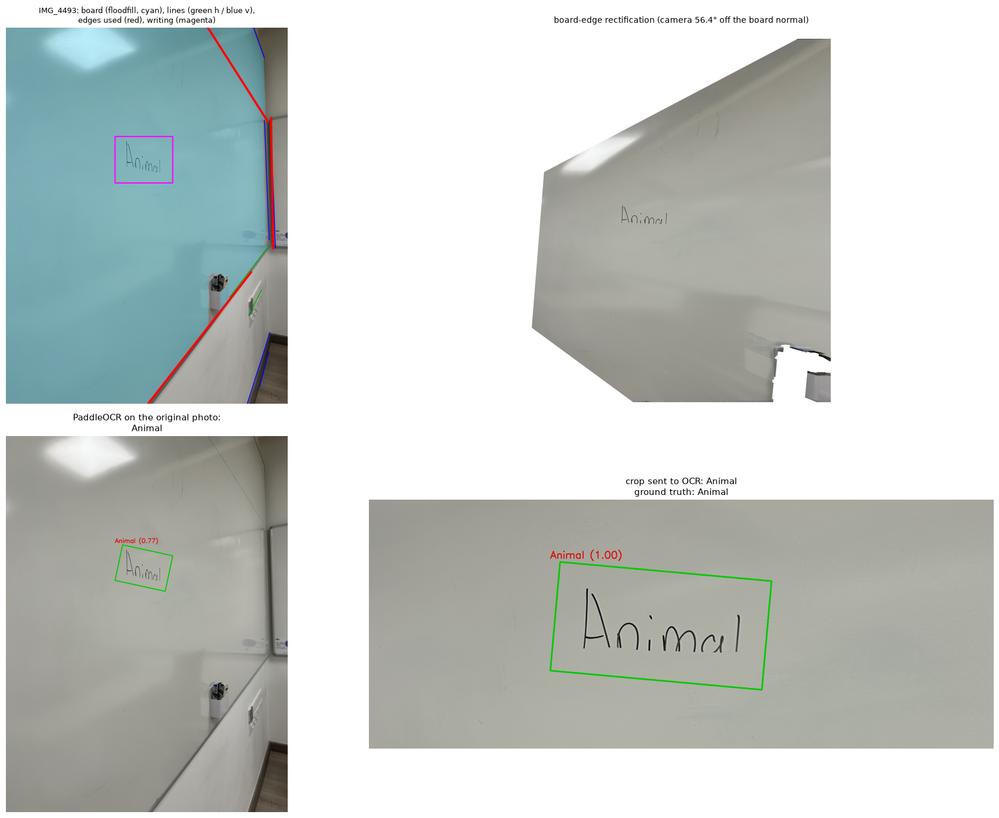

IMG_4494: board 94% of image | 5 long lines | rectified from top/bottom edges + no-roll assumption


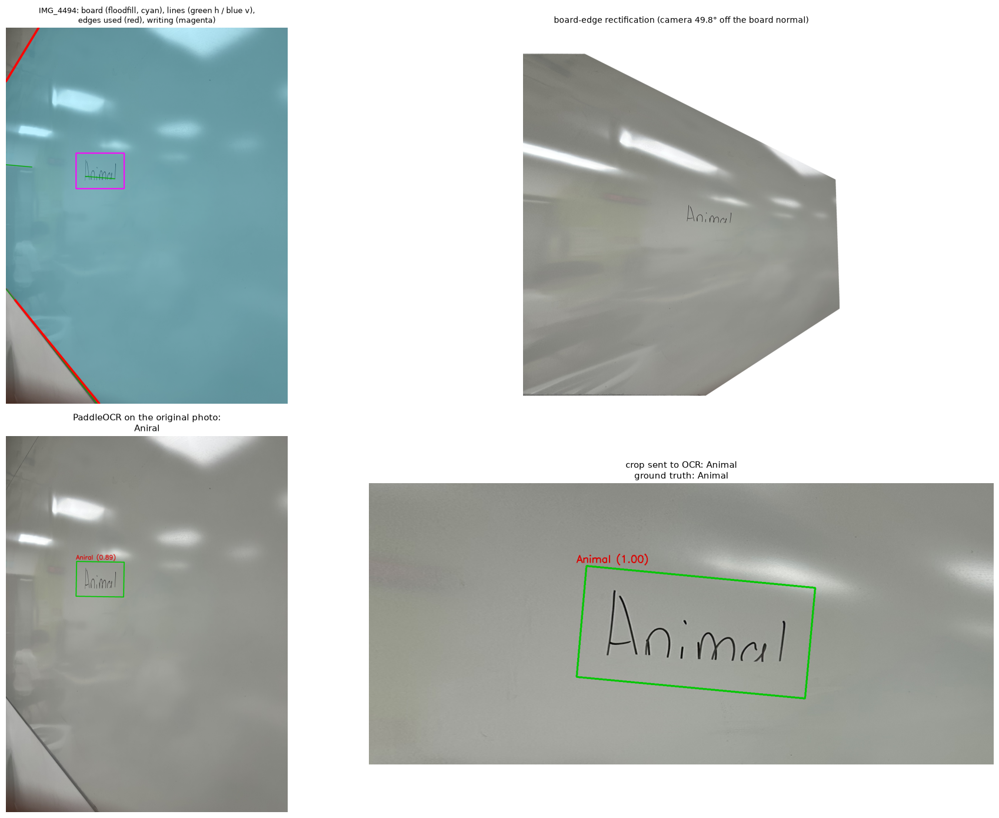

IMG_4495: board 85% of image | 8 long lines | rectified from top/bottom edges + no-roll assumption


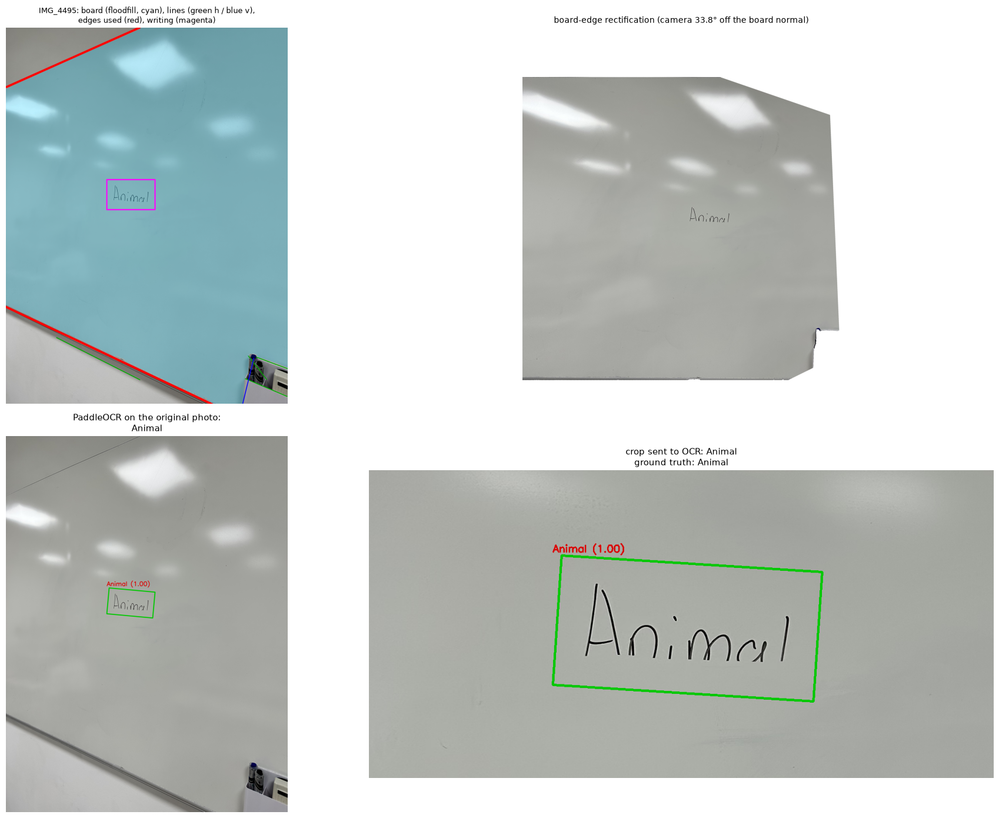

IMG_4497: board 69% of image | 42 long lines | rectified from top/bottom edges + no-roll assumption


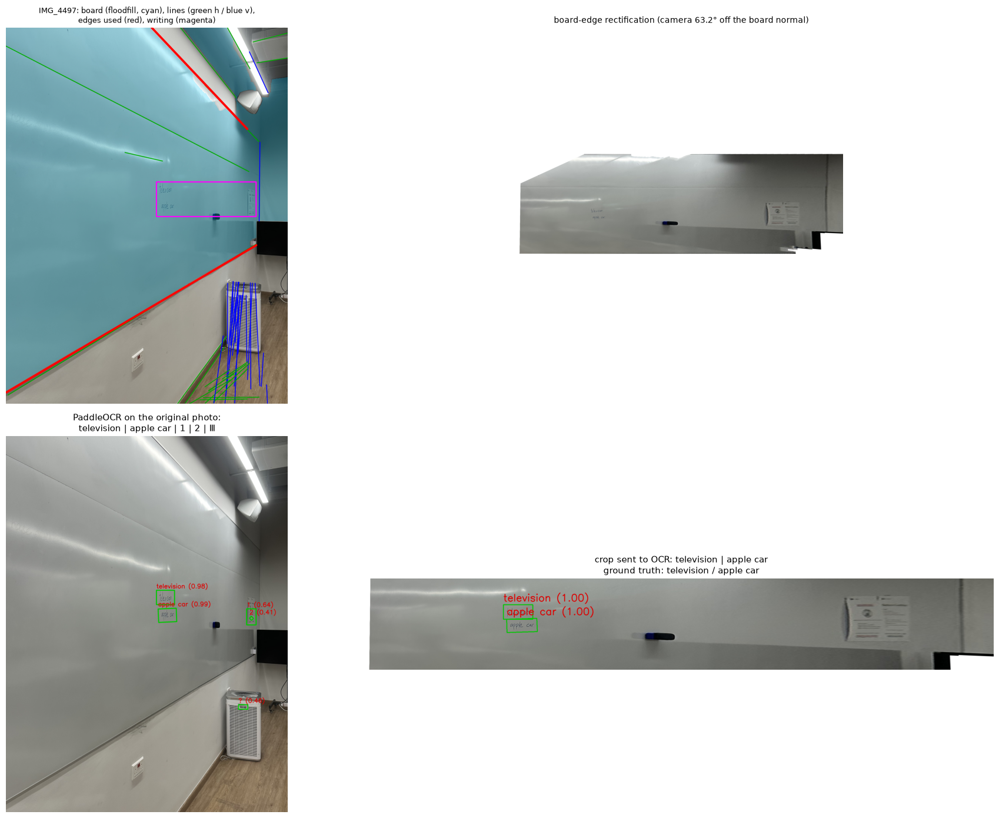

IMG_4498: board 80% of image | 37 long lines | rectified from top/bottom edges + no-roll assumption


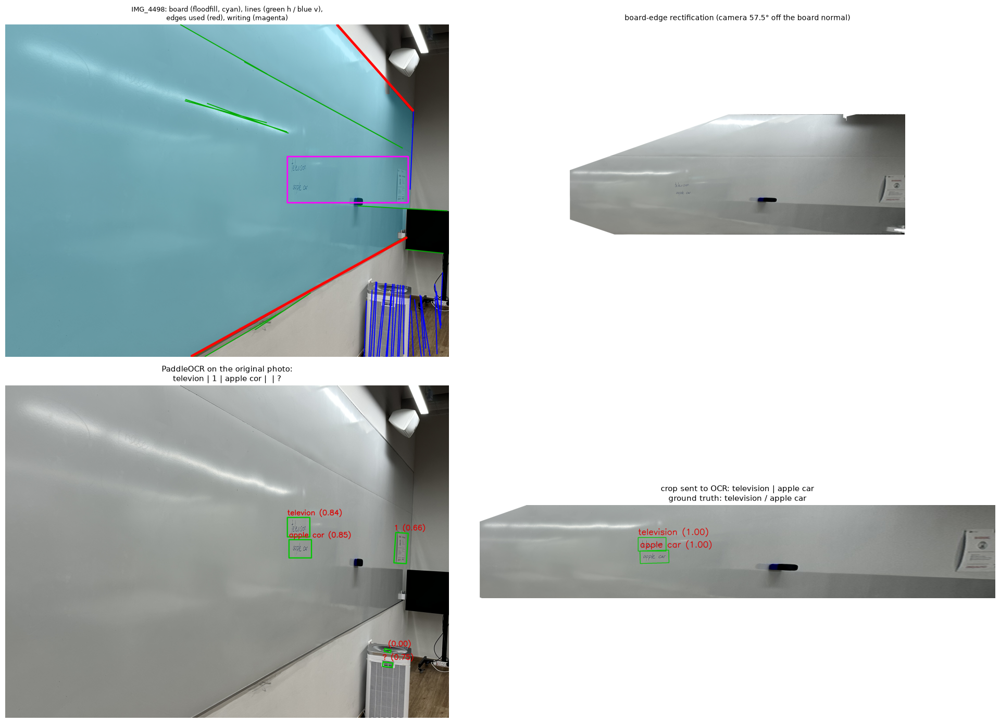

IMG_4499: board 96% of image | 4 long lines | rectified from top/bottom edges + no-roll assumption


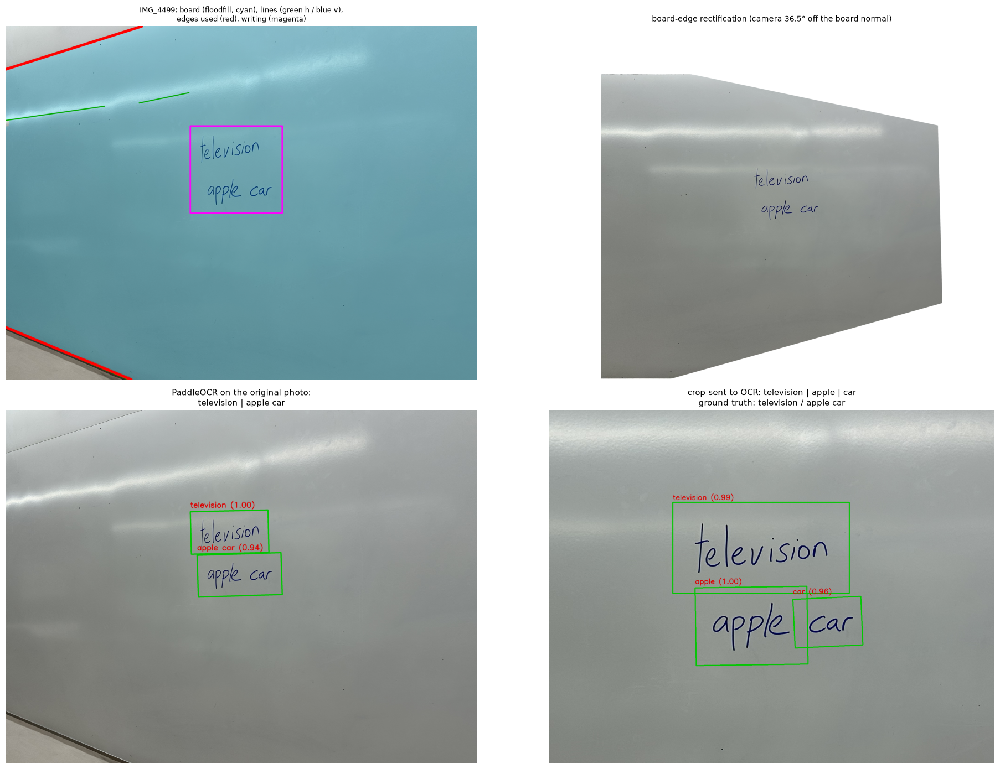

IMG_4500: board 92% of image | 5 long lines | rectified from top/bottom edges + no-roll assumption


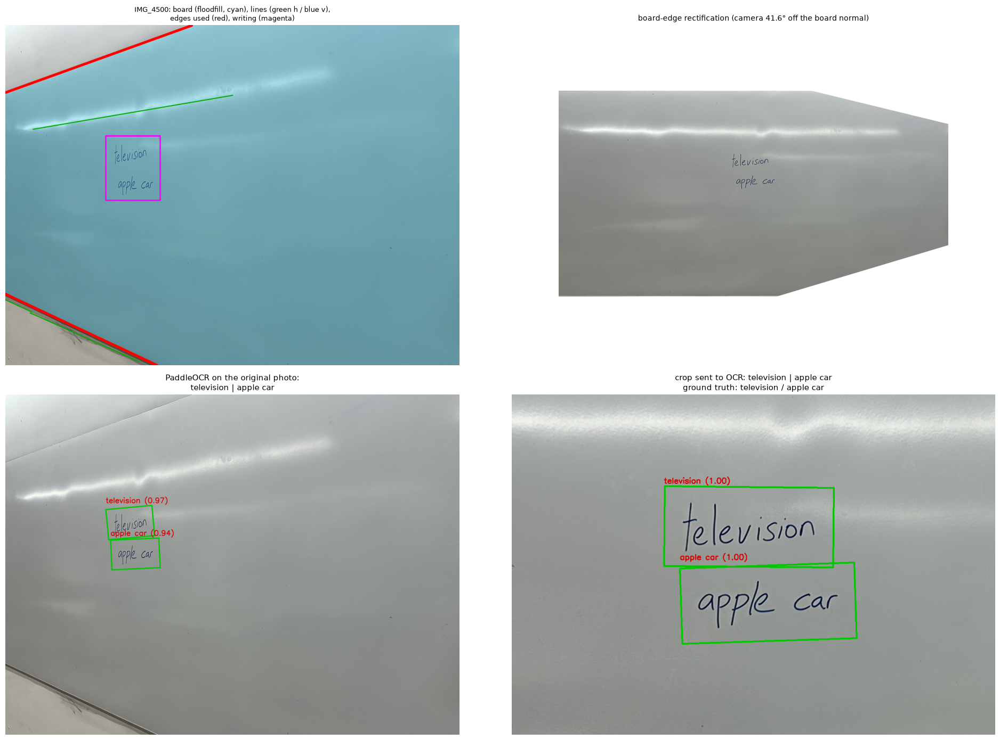

IMG_4501: board 88% of image | 5 long lines | rectified from top/bottom edges + no-roll assumption


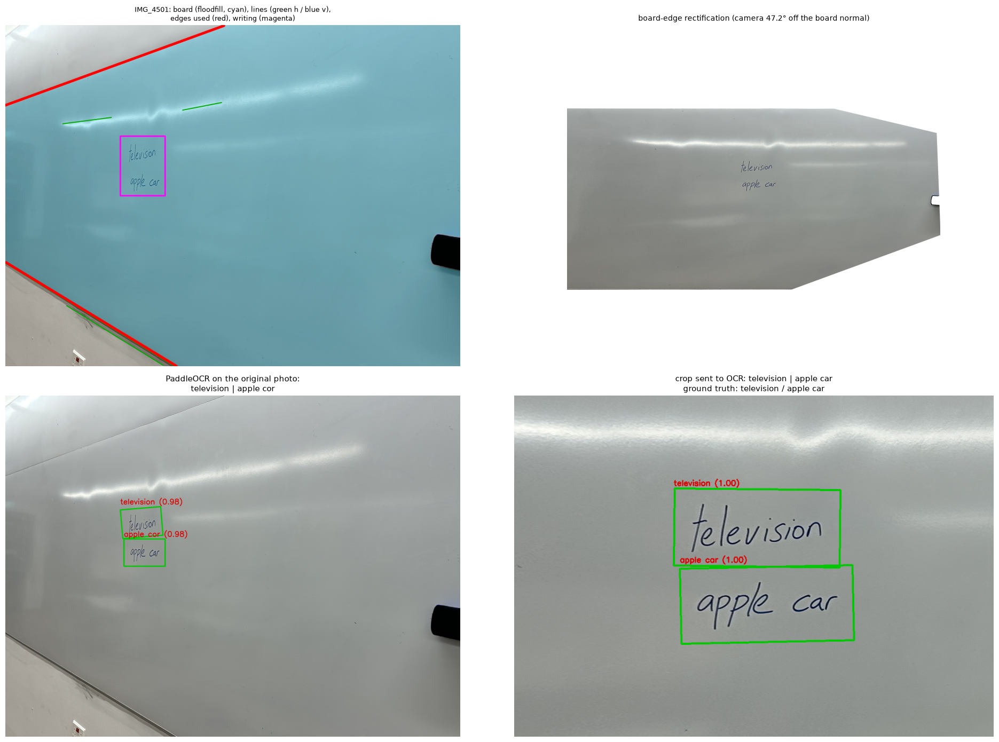

IMG_4502: board 87% of image | 6 long lines | rectified from top/bottom edges + no-roll assumption


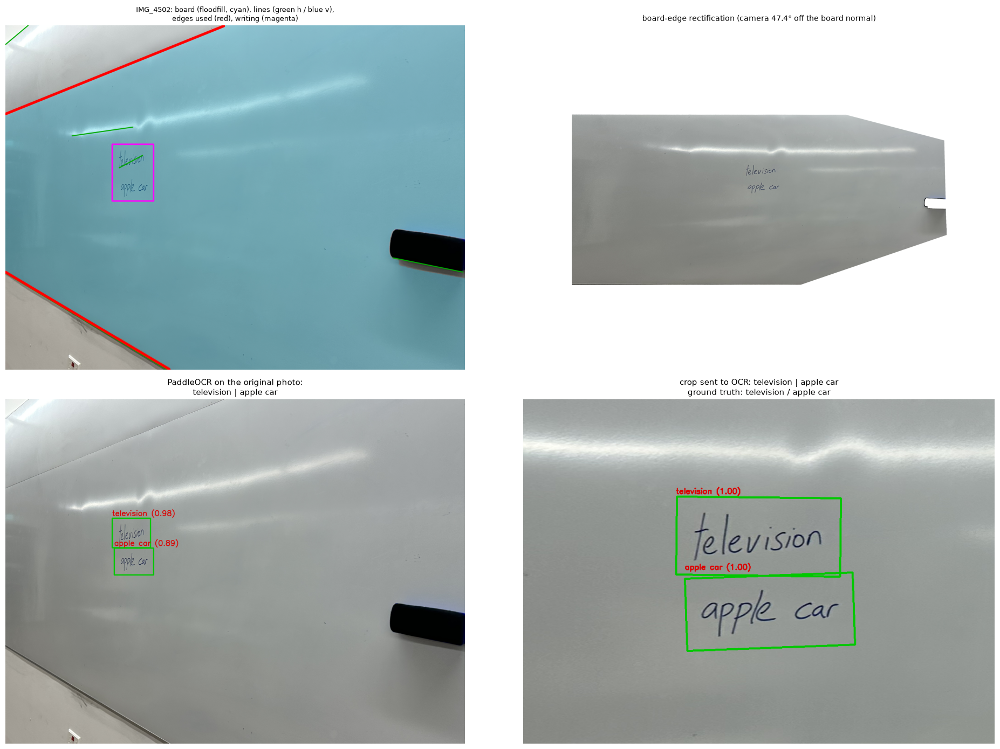

IMG_4503: board 91% of image | 9 long lines | rectified from top/bottom edges + no-roll assumption


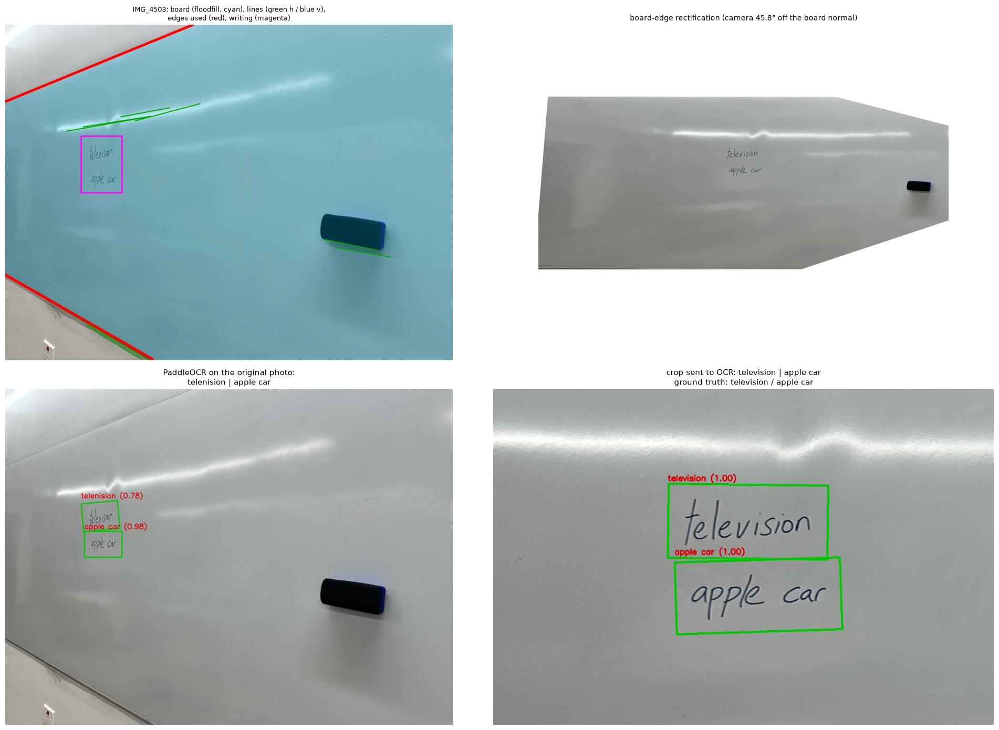

IMG_4504: board 91% of image | 4 long lines | rectified from top/bottom edges + no-roll assumption


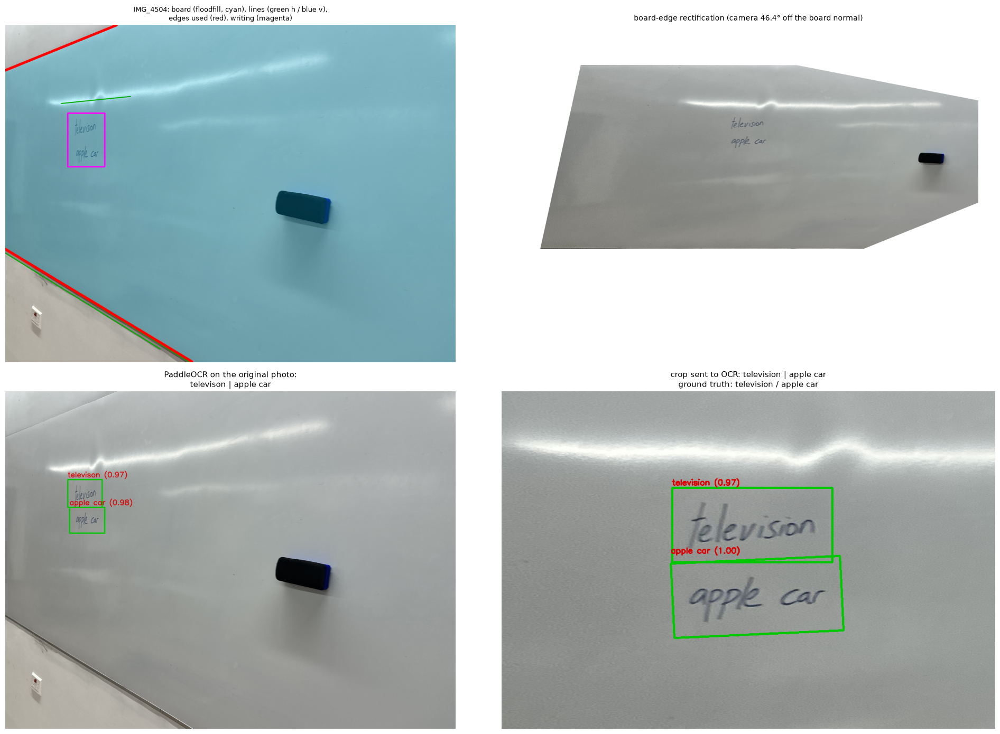

IMG_4505: board 92% of image | 3 long lines | rectified from top/bottom edges + no-roll assumption


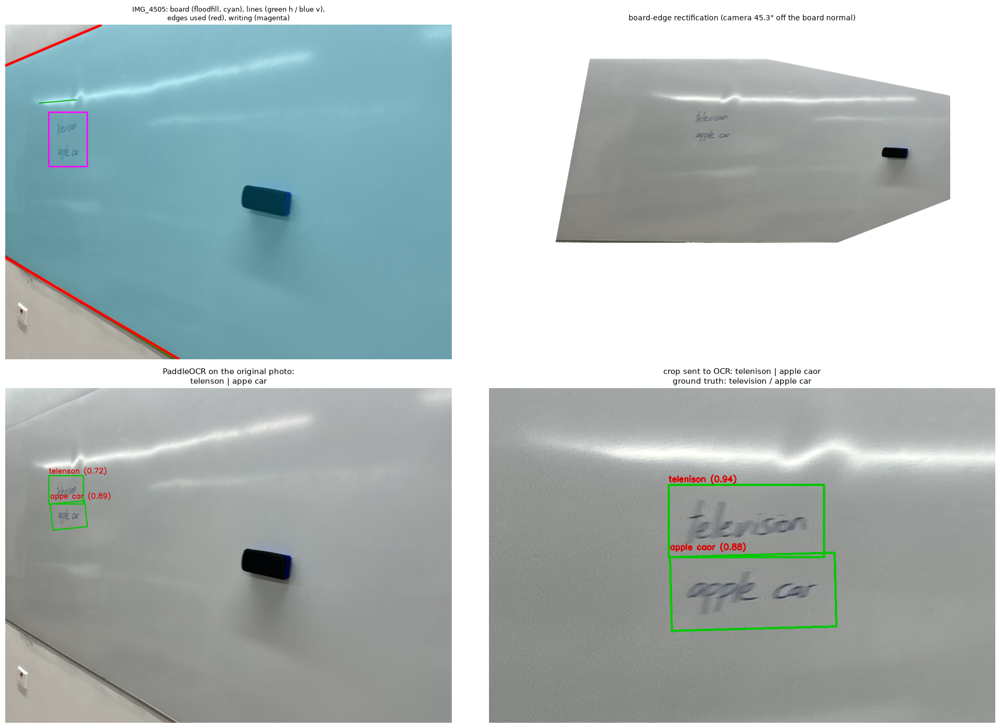

IMG_4508: board 97% of image | 6 long lines | rectified from top/bottom edges + no-roll assumption


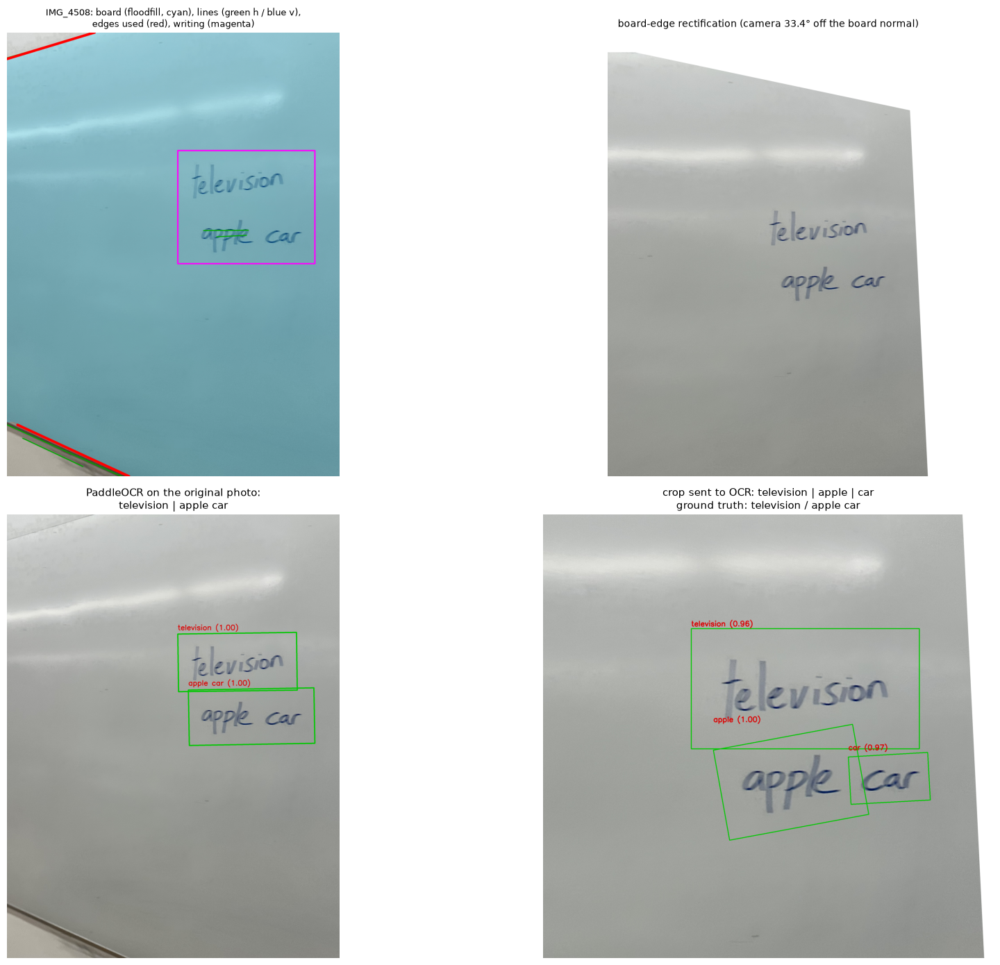

IMG_4512: board 40% of image | 80 long lines | rectified from top/bottom edges + no-roll assumption


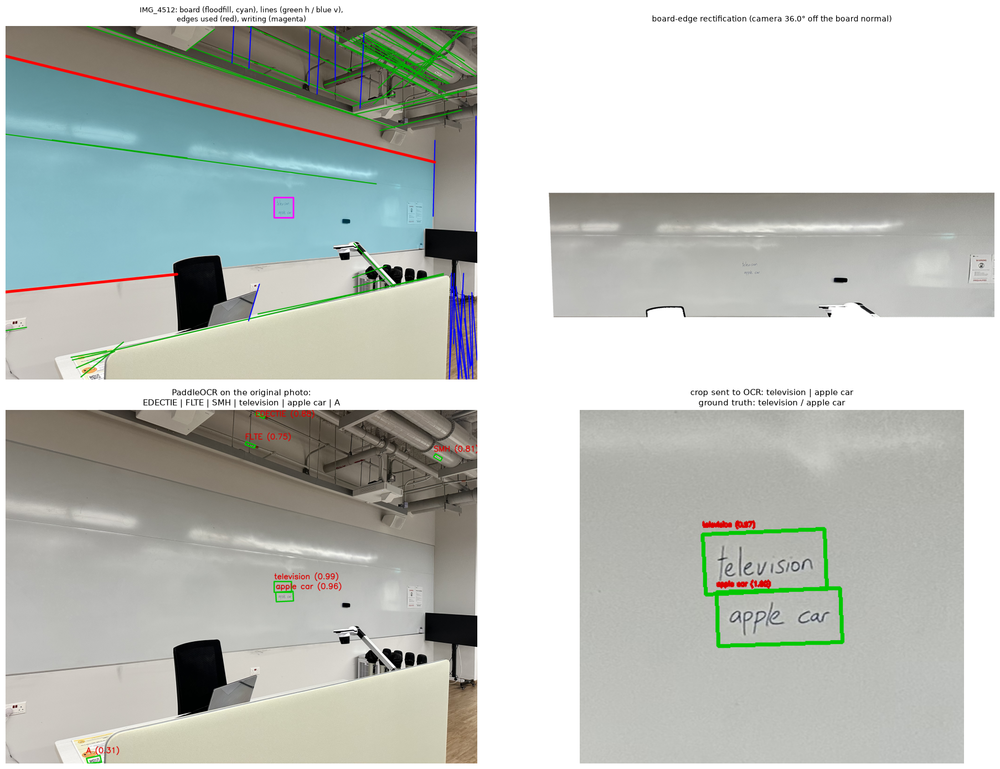

IMG_4513: board 40% of image | 82 long lines | rectified from top/bottom edges + no-roll assumption


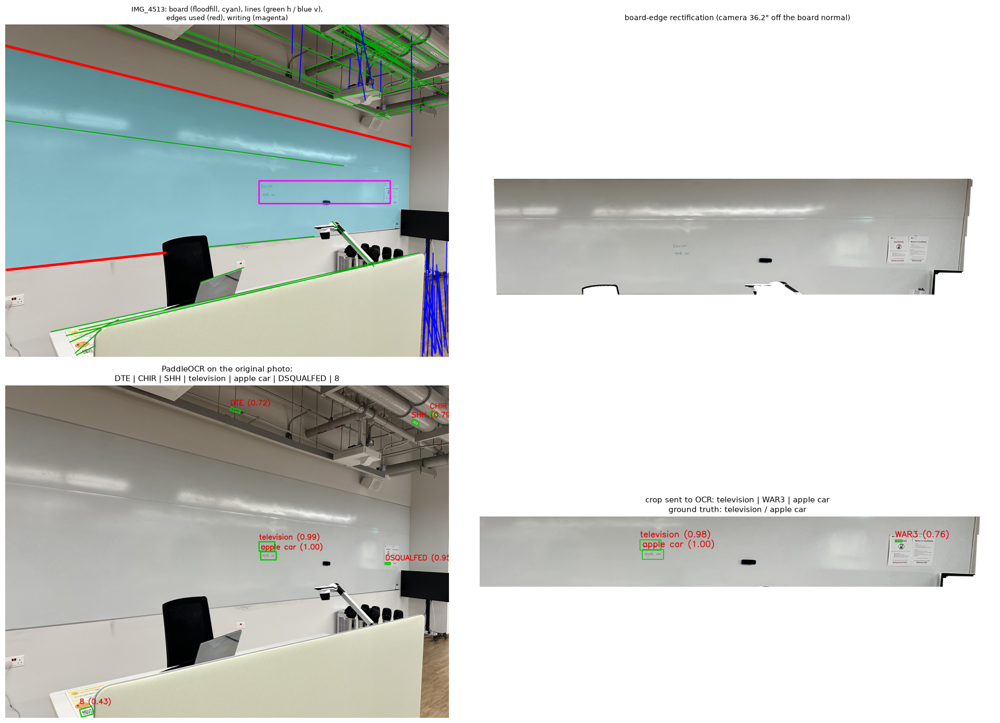

IMG_4514: board 24% of image | 124 long lines | rectified from top/bottom edges + reference line


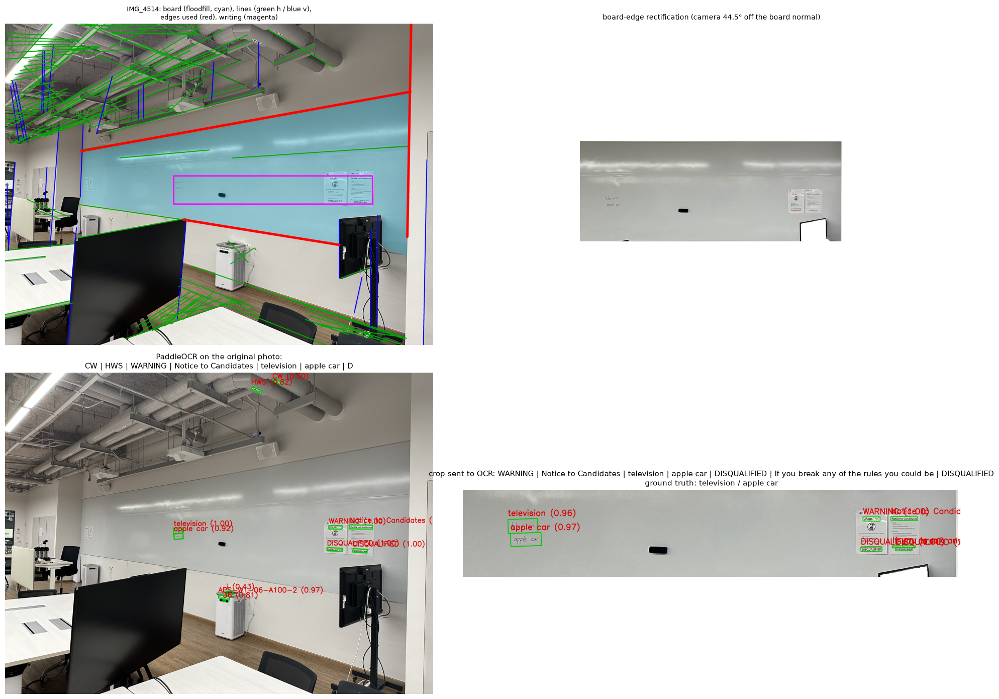

IMG_4515: board 34% of image | 59 long lines | rectified from top/bottom edges + no-roll assumption


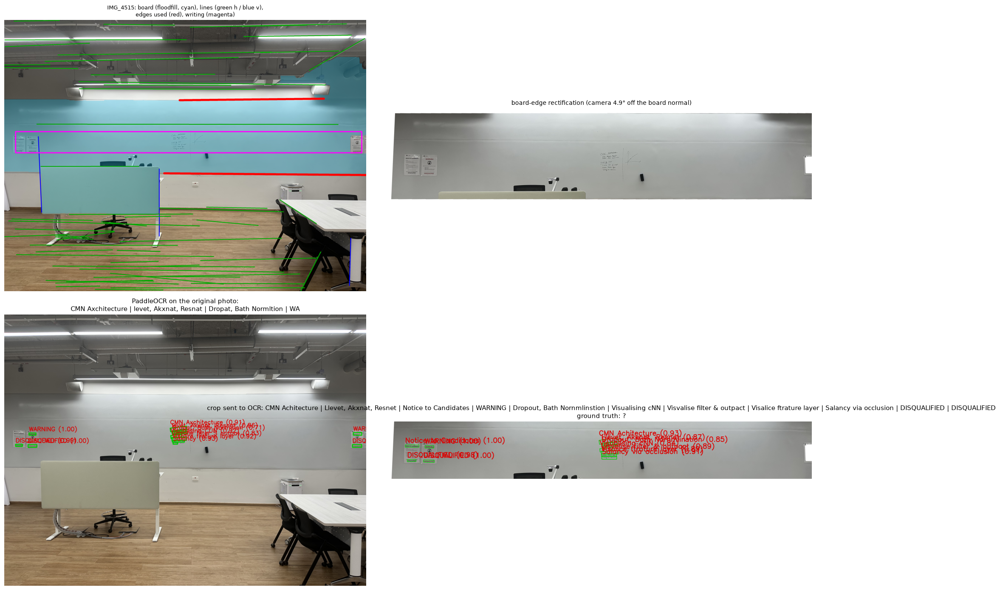

KeyboardInterrupt: 

In [17]:
AUTO_PHOTOS = sorted(WB_DIR.glob("*.jpg"))
SHOW_ONLY = None      # e.g. ["IMG_4498", "IMG_4513"] to process and plot only these photos; None = all
if SHOW_ONLY:
    AUTO_PHOTOS = [p for p in AUTO_PHOTOS if p.stem in SHOW_ONLY]

# ground truth: the lines of text written on the board, per photo (photos without an entry are just listed)
AUTO_GT = {name: ["Animal"] for name in ("IMG_4493", "IMG_4494", "IMG_4495")}
AUTO_GT.update({p.stem: ["television", "apple car"] for p in AUTO_PHOTOS if "IMG_4497" <= p.stem <= "IMG_4514"})


def draw_dets(img_bgr, dets, thick):
    # PaddleOCR detection boxes (green) with the recognised text and confidence
    vis = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    scale = max(img_bgr.shape[:2]) / 1500
    for text, score, poly in dets:
        pts = np.asarray(poly, np.int32).reshape(-1, 1, 2)
        cv2.polylines(vis, [pts], True, (0, 200, 0), thick)
        x, y = pts[:, 0, 0].min(), pts[:, 0, 1].min()
        cv2.putText(vis, f"{text.encode('ascii', 'replace').decode()} ({score:.2f})", (int(x), int(max(y - 8 * scale, 20 * scale))),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8 * scale, (220, 0, 0), max(2, int(2 * scale)))
    return vis


def plain(text):
    # keep plot titles printable: PaddleOCR sometimes reads non-Latin characters from noise
    return "".join(ch if ord(ch) < 0x2E80 else "?" for ch in text)


def show_photo(name, info):
    # one figure per photo (2x2): plane selection | rectified board / OCR on the original | OCR on the crop
    fig, ax = plt.subplots(2, 2, figsize=(20, 14))
    ax = [ax[0, 0], ax[0, 1], ax[1, 1], ax[1, 0]]
    vis = cv2.cvtColor(info["img"], cv2.COLOR_BGR2RGB)
    if info["mask"] is not None:
        tint = vis.copy(); tint[info["mask"] > 0] = (0, 200, 255)
        vis = cv2.addWeighted(vis, 0.75, tint, 0.25, 0)
    for e in info["lines"]:
        cv2.line(vis, tuple(map(int, e["p"])), tuple(map(int, e["q"])), (0, 170, 0) if e["kind"] == "h" else (0, 0, 255), 8)
    if info["choice"]:
        for e in [*info["choice"]["pair"], info["choice"]["ref"]]:
            if e is not None:
                cv2.line(vis, tuple(map(int, e["p"])), tuple(map(int, e["q"])), (255, 0, 0), 22)
    if info.get("source_quad") is not None:
        cv2.polylines(vis, [np.int32(info["source_quad"]).reshape(-1, 1, 2)],
                      True, (255, 0, 0), 16)
    if info["text"] is not None:
        x0, y0 = info["text"].min(0).astype(int); x1, y1 = info["text"].max(0).astype(int)
        cv2.rectangle(vis, (x0, y0), (x1, y1), (255, 0, 255), 12)
    ax[0].imshow(vis)
    ax[0].set_title(f"{name}: board ({SEG_METHOD}, cyan), lines (green h / blue v),\nedges used (red), writing (magenta)", fontsize=9)

    gt = " / ".join(AUTO_GT.get(name, ["?"]))
    if info["rectified"] is not None:
        ax[1].imshow(cv2.cvtColor(info["rectified"], cv2.COLOR_BGR2RGB))
        corrected_title = (f"board-edge rectification (camera {info['angle']:.1f}° off the board normal)"
                           if np.isfinite(info["angle"]) else info["status"])
        ax[1].set_title(corrected_title, fontsize=10)
        ax[2].imshow(draw_dets(info["crop"], info["crop_dets"], 3))
        ax[2].set_title(plain("crop sent to OCR: " + " | ".join(t for t, _, _ in info["crop_dets"])) + f"\nground truth: {gt}", fontsize=11)
    else:
        ax[1].text(0.5, 0.5, info["status"], ha="center", va="center", wrap=True); ax[2].set_visible(False)
    ax[3].imshow(draw_dets(info["img"], info["dets"], 10))
    ax[3].set_title(plain("PaddleOCR on the original photo:\n" + " | ".join(t for t, _, _ in info["dets"])[:70]), fontsize=11)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()


auto = {}
for path in AUTO_PHOTOS:
    img = load_upright(path)
    dets = ocr_detect(img)                                   # finds the writing; reused for the "original" score
    info = auto_rectify(img, path, dets=dets)
    info.update(img=img, dets=dets, crop_dets=[])
    if info["rectified"] is not None:
        info["crop_dets"] = ocr_detect(info["crop"], full_res=True)
        cv2.imwrite(str(PC_OUT / f"{path.stem}_auto_rectified.jpg"), info["rectified"])
        cv2.imwrite(str(PC_OUT / f"{path.stem}_auto_crop.jpg"), info["crop"])
    auto[path.stem] = info
    print(f"{path.stem}: board {0 if info['mask'] is None else (info['mask'] > 0).mean():.0%} of image | "
          f"{len(info['lines'])} long lines | {info['status']}")
    show_photo(path.stem, info)

In [ ]:
from paddleocr import TextRecognition
import pandas as pd
import time

rec_model = TextRecognition(model_name="PP-OCRv6_medium_rec")    # recognizer only (reads one text line per image)


def plain(text):
    # keep plot titles printable: PaddleOCR sometimes reads non-Latin characters from noise
    return "".join(ch if ord(ch) < 0x2E80 else "?" for ch in text)

# ---------- 9.1 tiled text detection at full resolution ----------
TILE      = 1600    # tile size (px): same memory as the 1600 px whole-photo detection, but no shrinking
OVERLAP   = 400     # overlap between tiles, so a text line cut by one tile appears whole in the next


def _box_area(p):
    return cv2.contourArea(np.float32(p).reshape(-1, 2))


def tiled_ocr(img_bgr, tile=TILE, overlap=OVERLAP):
    # PaddleOCR on overlapping full-resolution tiles; duplicate boxes from overlaps are merged
    h, w = img_bgr.shape[:2]
    step = tile - overlap
    xs = list(range(0, max(w - tile, 0) + 1, step)); xs += [w - tile] if xs[-1] + tile < w else []
    ys = list(range(0, max(h - tile, 0) + 1, step)); ys += [h - tile] if ys[-1] + tile < h else []
    dets = []
    for y0 in ys:
        for x0 in xs:
            t = img_bgr[max(y0, 0):y0 + tile, max(x0, 0):x0 + tile]
            for text, score, poly in ocr_detect(t):
                dets.append((text, score, np.asarray(poly, float).reshape(-1, 2) + [max(x0, 0), max(y0, 0)]))
    # merge: if a box lies mostly inside a bigger one (same text seen twice / cut at a tile edge), keep the bigger
    dets.sort(key=lambda d: -_box_area(d[2]))
    kept = []
    for d in dets:
        a = np.int32(d[2]); area = max(_box_area(a), 1)
        dup = False
        for k in kept:
            inter, _ = cv2.intersectConvexConvex(np.float32(a), np.float32(k[2]))
            if inter / area > 0.5:
                dup = True
                break
        if not dup:
            kept.append(d)
    return kept


# ---------- 9.2 line heights ----------
def line_height(poly):
    # height of a (roughly horizontal) text-line box: mean of its two short sides
    p = np.asarray(poly, float).reshape(-1, 2)
    if len(p) != 4:
        return float(np.ptp(p[:, 1]))
    return float((np.linalg.norm(p[0] - p[3]) + np.linalg.norm(p[1] - p[2])) / 2)


# ---------- 9.3 enlargement methods ----------
TARGET_H = 64       # enlarge text-line crops to about this box height (PaddleOCR's recognizer reads lines at 48 px)
MAX_SCALE = 4.0
SR_DIR = ROOT / "models" / "superres"
_sr_cache = {}


def _sr(name, k):
    # OpenCV dnn_superres model (ESPCN / FSRCNN / EDSR), x2/x3/x4
    key = (name, k)
    if key not in _sr_cache:
        m = cv2.dnn_superres.DnnSuperResImpl_create()
        m.readModel(str(SR_DIR / f"{name.upper()}_x{k}.pb"))
        m.setModel(name.lower(), k)
        _sr_cache[key] = m
    return _sr_cache[key]


def enlarge(img, s, method):
    # enlarge an image by factor s with the given method
    if s <= 1.05 or method == "none":
        return img
    size = (int(round(img.shape[1] * s)), int(round(img.shape[0] * s)))
    if method == "bicubic":
        return cv2.resize(img, size, interpolation=cv2.INTER_CUBIC)
    if method == "lanczos":
        return cv2.resize(img, size, interpolation=cv2.INTER_LANCZOS4)
    if method == "bicubic+sharpen":
        up = cv2.resize(img, size, interpolation=cv2.INTER_CUBIC)
        blur = cv2.GaussianBlur(up, (0, 0), sigmaX=0.8 * s)
        return cv2.addWeighted(up, 1.6, blur, -0.6, 0)           # unsharp mask: strengthens stroke edges
    # learned super-resolution: smallest model scale >= s (x2..x4), then exact resize
    k = int(min(4, max(2, np.ceil(s))))
    up = _sr(method, k).upsample(img)
    return cv2.resize(up, size, interpolation=cv2.INTER_AREA if k > s else cv2.INTER_CUBIC)


def quad_crop(img, poly):
    # cut a text line along its own (possibly tilted) box, like PaddleOCR does internally
    p = np.float32(np.asarray(poly, float).reshape(-1, 2))
    if len(p) != 4:
        p = np.float32(cv2.boxPoints(cv2.minAreaRect(p)))
    # order TL, TR, BR, BL
    s_, d_ = p.sum(1), np.diff(p, axis=1).ravel()
    p = np.float32([p[s_.argmin()], p[d_.argmin()], p[s_.argmax()], p[d_.argmax()]])
    w = int(round(max(np.linalg.norm(p[0] - p[1]), np.linalg.norm(p[3] - p[2]))))
    h = int(round(max(np.linalg.norm(p[0] - p[3]), np.linalg.norm(p[1] - p[2]))))
    M = cv2.getPerspectiveTransform(p, np.float32([[0, 0], [w, 0], [w, h], [0, h]]))
    return cv2.warpPerspective(img, M, (max(w, 1), max(h, 1)), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def line_crops(img, dets):
    # every detected text line cut along its box, with its box height (px)
    return [dict(crop=quad_crop(img, poly), height=line_height(poly), box=np.asarray(poly, float).reshape(-1, 2), text0=text)
            for text, score, poly in dets]


def read_lines(lines, method, target_h=TARGET_H):
    # enlarge each line crop so its box is about target_h tall, then recognise it
    ims = [enlarge(l["crop"], float(np.clip(target_h / max(l["height"], 1), 1, MAX_SCALE)), method) for l in lines]
    res = rec_model.predict(ims) if ims else []
    return [(r["rec_text"], float(r["rec_score"]), l["box"]) for r, l in zip(res, lines)]

REGION_SCALE  = 3.0                 # upscale factor for text regions
REGION_METHOD = "espcn"             # enlargement method for regions (see 9.3); "bicubic+sharpen" needs no model file
REGION_MAX    = 4000                # PaddleOCR shrinks anything larger than this, so cap the upscaled region size


def merge_dets(dets, overlap=0.5):
    # drop boxes that lie mostly inside a bigger box (the same text found twice)
    dets = sorted(dets, key=lambda d: -_box_area(d[2]))
    kept = []
    for d in dets:
        a = np.float32(np.asarray(d[2], float).reshape(-1, 2)); area = max(_box_area(a), 1)
        if all(cv2.intersectConvexConvex(a, np.float32(k[2]))[0] / area <= overlap for k in kept):
            kept.append((d[0], d[1], a))
    return kept


def text_regions(dets, img_shape, grow=1.5, margin=0.6):
    # group nearby text boxes into clusters; one full-resolution region (with margin) per cluster
    h, w = img_shape[:2]
    rects = []
    for _, _, poly in dets:
        p = np.asarray(poly, float).reshape(-1, 2); lh = line_height(p)
        rects.append([*(p.min(0) - grow * lh), *(p.max(0) + grow * lh), lh])
    parent = list(range(len(rects)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    for i in range(len(rects)):
        for j in range(i + 1, len(rects)):
            a, b = rects[i], rects[j]
            if a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]:     # expanded boxes touch
                parent[find(i)] = find(j)
    groups = {}
    for i in range(len(rects)):
        groups.setdefault(find(i), []).append(i)
    regions = []
    for idx in groups.values():
        pts = np.vstack([np.asarray(dets[i][2], float).reshape(-1, 2) for i in idx])
        lh = np.median([rects[i][4] for i in idx])
        (x0, y0), (x1, y1) = pts.min(0), pts.max(0)
        mx, my = max(margin * (x1 - x0), 4 * lh), max(margin * (y1 - y0), 4 * lh)    # quick pass may miss nearby lines
        regions.append([int(max(0, x0 - mx)), int(max(0, y0 - my)), int(min(w, x1 + mx)), int(min(h, y1 + my))])
    # merge regions that overlap (e.g. two parts of the same notice), so no area is processed twice
    merged = True
    while merged:
        merged = False
        for i in range(len(regions)):
            for j in range(i + 1, len(regions)):
                a, b = regions[i], regions[j]
                if a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]:
                    regions[i] = [min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3])]
                    regions.pop(j); merged = True
                    break
            if merged:
                break
    return [tuple(r) for r in regions]


def upscale_regions_ocr(img_bgr, quick_dets=None, scale=REGION_SCALE, method=REGION_METHOD):
    # quick detection -> regions around the found text -> upscale each region -> detect + read -> photo coordinates
    quick_dets = ocr_detect(img_bgr) if quick_dets is None else quick_dets
    if not quick_dets:
        return tiled_ocr(img_bgr), []                         # nothing found at all: scan the whole photo instead
    regions = text_regions(quick_dets, img_bgr.shape)
    out = []
    for x0, y0, x1, y1 in regions:
        s = min(scale, REGION_MAX / max(x1 - x0, y1 - y0))   # keep the upscaled region under PaddleOCR's size limit
        up = enlarge(img_bgr[y0:y1, x0:x1], s, method)
        sx, sy = up.shape[1] / (x1 - x0), up.shape[0] / (y1 - y0)
        for text, score, poly in ocr_detect(up, full_res=True):
            p = np.asarray(poly, float).reshape(-1, 2) / [sx, sy] + [x0, y0]
            out.append((text, score, p))
    return merge_dets(out), regions


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/zhaobao/.paddlex/official_models/PP-OCRv6_medium_rec`.


### 8.4b How the whiteboard was found (segmentation comparison)

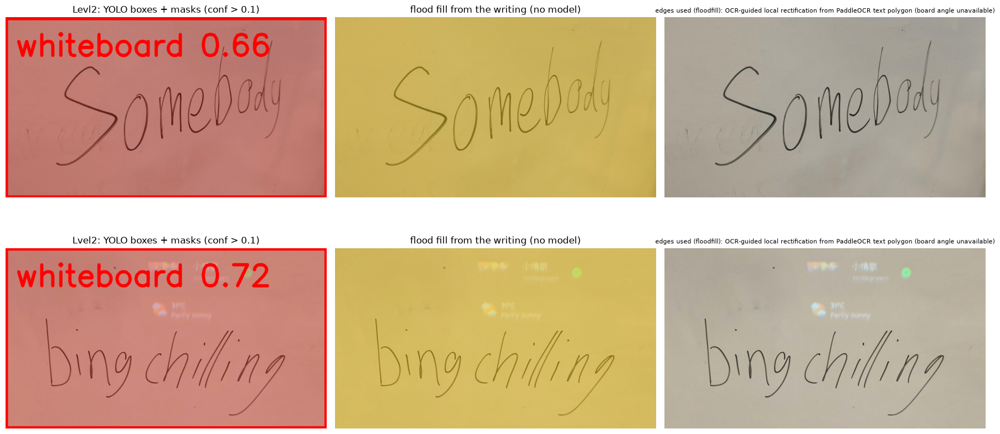

In [ ]:
# How the board was found: YOLO's raw detections (bounding box + confidence + mask, every instance)
# next to the flood-fill region, and the edges the pipeline used
SHOW = [p.stem for p in AUTO_PHOTOS][:4]          # choose photos to inspect, e.g. ["IMG_4498", "IMG_4513"]
cols = 3 if seg_model is not None else 2
fig, axes = plt.subplots(len(SHOW), cols, figsize=(6 * cols, 4.6 * len(SHOW)), squeeze=False)
for row, name in zip(axes, SHOW):
    info = auto[name]; img = info["img"]; h, w = img.shape[:2]
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    k = 0
    if seg_model is not None:
        r = seg_model.predict(preprocess_like_roboflow(img), imgsz=SEG_SIZE, conf=0.1, retina_masks=True, verbose=False)[0]
        vis = rgb.copy()
        if r.masks is not None:
            for j, (m, b, c) in enumerate(zip(r.masks.data.cpu().numpy(), r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())):
                col = [(255, 0, 0), (0, 160, 255), (0, 200, 0), (200, 0, 200)][j % 4]
                mk = cv2.resize(m, (w, h)) > 0.5
                tint = vis.copy(); tint[mk] = col; vis = cv2.addWeighted(vis, 0.75, tint, 0.25, 0)
                x0, y0, x1, y1 = (b * np.array([w / SEG_SIZE, h / SEG_SIZE] * 2)).astype(int)
                cv2.rectangle(vis, (x0, y0), (x1, y1), col, 18)
                cv2.putText(vis, f"whiteboard {c:.2f}", (x0 + 40, y0 + 150), cv2.FONT_HERSHEY_SIMPLEX, 4, col, 12)
        row[k].imshow(vis); row[k].set_title(f"{name}: YOLO boxes + masks (conf > 0.1)"); k += 1
    fm, _ = segment_board_floodfill(img, text_boxes(info["dets"]))
    vis = rgb.copy(); tint = vis.copy(); tint[fm > 0] = (255, 200, 0); vis = cv2.addWeighted(vis, 0.6, tint, 0.4, 0)
    row[k].imshow(vis); row[k].set_title("flood fill from the writing (no model)"); k += 1
    vis = rgb.copy()
    if info["choice"]:
        for e in info["choice"]["pair"]:
            cv2.line(vis, tuple(map(int, e["p"])), tuple(map(int, e["q"])), (255, 0, 0), 24)
    row[k].imshow(vis); row[k].set_title(f"edges used ({SEG_METHOD}): {info['status']}", fontsize=8)
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()

### 8.5 OCR: original vs automatically rectified

- **original (full)**: the whole photo (detection at max 1600 px)
- **original (crop)**: the same crop-around-the-writing step, but without perspective correction. This isolates the effect of the correction itself.
- **auto-rectified (crop)**: the output of this section

In [ ]:
def read_text(dets):
    # all recognised text, top-to-bottom then left-to-right
    order = sorted(dets, key=lambda d: (round(np.asarray(d[2])[:, 1].mean() / 80), np.asarray(d[2])[:, 0].mean()))
    return " ".join(t for t, s, _ in order if t.strip())

print(f"{'image':<10} {'version':<22} {'CER':>5}  text read")
print("-" * 80)
auto_rows = []
for name, info in auto.items():
    gt = AUTO_GT.get(name)
    versions = [("original (full)", info["dets"])]
    if info["rectified"] is not None:
        versions += [("original (crop)", ocr_detect(info["crop_original"], full_res=True)),
                     ("auto-rectified (crop)", info["crop_dets"])]          # computed in 8.4
    for version, dets in versions:
        text = read_text(dets)
        if gt:
            # each written line vs its best-matching detection, averaged (other text in the photo is ignored)
            cer = float(np.mean([best_match(dets, line)[1] for line in gt]))
        else:
            cer = float("nan")
        auto_rows.append((name, version, cer, text))
        print(f"{name:<10} {version:<22} {cer:>5.2f}  {text[:60]}")
    print()

# summary: mean CER over the photos with ground truth
import pandas as pd
df = pd.DataFrame(auto_rows, columns=["image", "version", "CER", "text"]).dropna(subset=["CER"])
summary = df.pivot(index="image", columns="version", values="CER")
display(summary.round(3))
print("mean CER per version (photos rectified by the pipeline only):")
print(summary.dropna().mean().round(3).to_string())

image      version                  CER  text read
--------------------------------------------------------------------------------
Levl2      original (full)          nan  Somesaly
Levl2      original (crop)          nan  Somesaly
Levl2      auto-rectified (crop)    nan  Sorcdaly

Lvel2      original (full)          nan  bingchiling
Lvel2      original (crop)          nan  bingchiling
Lvel2      auto-rectified (crop)    nan  bingchiling



version
image


mean CER per version (photos rectified by the pipeline only):
Series([], )


**Limitations**
- **Needs two board edges around the writing** (top and bottom, or left and right). A close-up with no board edge in view is left unrectified.
- **Line detection can pick the wrong lines** when the room has strong straight lines near the board (shelves, door frames, reflections of light fittings). The "writing between the two lines" and "on the segmented board" checks reduce this but don't remove it.
- **Vertical reference:** only lines at least 25% of the photo's height are trusted. Short slanted objects (e.g. a marker in a holder) are ignored, and the no-roll assumption is used instead.
- **Better segmentation**, from fine-tuning YOLO on our own labelled side-view photos, would make step 1 reliable enough to also mask out the wall precisely.

---
## 9. Small / far-away text: tiled detection + enlargement

Two separate problems when the writing is far away:

1. **Finding the text.** To save memory, PaddleOCR normally looks at a **shrunk copy** of the photo (1600 px long side; the phone photo is 4032 px). Handwriting that is ~15–20 px tall in the photo becomes ~7 px and is **missed**.
   → **Tiled detection**: run PaddleOCR on overlapping **full-resolution tiles** (1600 × 1600, 400 px overlap) and merge the boxes. Same memory per step, no shrinking, but slower.
2. **Reading the text.** Each line is cut along its box and **enlarged** ("zooming in" for the model) so the line box is about `TARGET_H` = 64 px tall, then read by PaddleOCR's recognizer. Methods compared:

| Method | What it is |
|---|---|
| `none` | no enlargement (the recognizer resizes lines to 48 px itself) |
| `bicubic`, `lanczos` | standard interpolation (like zooming on the phone) |
| `bicubic+sharpen` | bicubic + unsharp mask (strengthens pen-stroke edges) |
| `espcn`, `fsrcnn`, `edsr` | learned super-resolution (OpenCV `dnn_superres`, models in `models/superres/`); trained on natural photos, so they may not suit handwriting |

> Requires the cells above (8.0–8.3). Loads one extra model (PaddleOCR text recognizer).

In [18]:
import torch
import os
from pathlib import Path
import cv2
import numpy as np
import jiwer
import matplotlib.pyplot as plt
from PIL import Image

WB_DIR   = ROOT / "Airdrop" / "converted"          # side-view whiteboard photos
PC_OUT   = ROOT / "outputs" / "perspective_correction"
PC_OUT.mkdir(parents=True, exist_ok=True)
MAX_SIDE = 4000                                     # max width/height of a rectified image (px)
print(ROOT)

def load_upright(path):
    # cv2.imread applies the EXIF orientation, so iPhone portrait photos come out upright
    img = cv2.imread(str(path))
    assert img is not None, f"cannot read {path}"
    return img


def camera_matrix_from_exif(path, w, h):
    # K from the EXIF 35 mm-equivalent focal length (a 35 mm frame is 36 mm wide)
    exif = Image.open(path).getexif().get_ifd(0x8769)
    f35 = exif.get(0xA405)                       # FocalLengthIn35mmFilm
    if not f35:
        f35 = 26                                 # typical phone main camera; used when EXIF is missing
        print(f"  no 35mm focal length in EXIF, assuming {f35} mm")
    f = f35 / 36.0 * max(w, h)
    return np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1.0]])


def line_through(p, q):
    # homogeneous line through two image points
    return np.cross([*p, 1.0], [*q, 1.0])


def best_match(dets, gt):
    # detection with the lowest CER against gt (case-insensitive); stray detections don't count against it
    if not dets:
        return None, 1.0
    scored = [(jiwer.cer(gt.lower(), t.lower() or " "), t, s, p) for t, s, p in dets]
    cer, t, s, p = min(scored, key=lambda x: x[0])
    return (t, s, p), min(cer, 1.0)

/Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment


### 9.1 Functions

### 9.2 Test photo and ground truth

`IMG_4547`: a far-away, almost frontal photo; the lowercase handwriting is only ~10 px tall in the photo.

In [20]:
SMALL_PHOTO = "IMG_4547"
SMALL_GT = ["CNN Architecture", "LeNet, Alexnet, Resnet", "Dropout, Batch Normalization", "Visualising CNN",
            "Visualise filter & output", "Visualise feature layer", "Saliency via occlusion"]


def score_lines(dets, gt=SMALL_GT):
    # each ground-truth line vs its best-matching detection: (mean CER, [(gt, read, cer), ...])
    per = [best_match(dets, g) for g in gt]
    return float(np.mean([c for _, c in per])), [(g, b[0] if b else "-", c) for g, (b, c) in zip(gt, per)]


small_path = WB_DIR / f"{SMALL_PHOTO}.jpg"
small_img = load_upright(small_path)

t0 = time.time(); det_whole = ocr_detect(small_img); t_whole = time.time() - t0     # whole photo shrunk to 1600 px
t0 = time.time(); det_tiled = tiled_ocr(small_img); t_tiled = time.time() - t0      # full-resolution tiles

rows = []
for name, d, tt in (("whole photo (shrunk to 1600 px)", det_whole, t_whole), ("tiled, full resolution", det_tiled, t_tiled)):
    cer, per = score_lines(d)
    rows.append((name, f"{sum(c < 0.5 for *_, c in per)} / {len(SMALL_GT)}", round(cer, 3), round(tt, 1)))
display(pd.DataFrame(rows, columns=["text detection", "lines found", "mean CER", "time (s)"]))

,text detection,lines found,mean CER,time (s)
0,whole photo (shrunk to 1600 px),4 / 7,0.429,6.0
1,"tiled, full resolution",7 / 7,0.160,79.4


#### What each detection found (zoomed on the writing; green = box, red = text read)

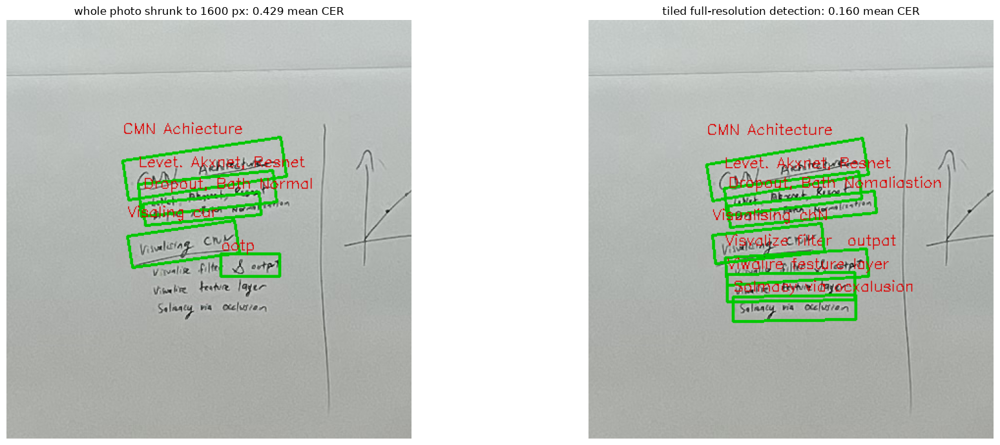

In [21]:
def text_region(dets, gt=SMALL_GT, margin=120):
    # bounding box of the detections that match the ground-truth lines (to zoom the figure on the writing)
    polys = [best_match(dets, g)[0][2] for g in gt if best_match(dets, g)[0] is not None]
    pts = np.vstack([np.asarray(p, float).reshape(-1, 2) for p in polys])
    x0, y0 = (pts.min(0) - margin).astype(int); x1, y1 = (pts.max(0) + margin).astype(int)
    return max(x0, 0), max(y0, 0), x1, y1


x0, y0, x1, y1 = text_region(det_tiled)
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
for a, (name, d) in zip(ax, (("whole photo shrunk to 1600 px", det_whole), ("tiled full-resolution detection", det_tiled))):
    vis = cv2.cvtColor(small_img[y0:y1, x0:x1].copy(), cv2.COLOR_BGR2RGB)
    for text, score, poly in d:
        p = np.asarray(poly, float).reshape(-1, 2) - [x0, y0]
        if (p[:, 0].max() < 0) or (p[:, 1].max() < 0) or (p[:, 0].min() > x1 - x0) or (p[:, 1].min() > y1 - y0):
            continue
        cv2.polylines(vis, [np.int32(p)], True, (0, 200, 0), 2)
        cv2.putText(vis, plain(text), (int(p[:, 0].min()), int(p[:, 1].min()) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (220, 0, 0), 1)
    a.imshow(vis); a.set_title(f"{name}: {score_lines(d)[0]:.3f} mean CER"); a.axis("off")
plt.tight_layout(); plt.show()

### 9.3 Enlarge each line before reading: method comparison

Lines come from the tiled detection. Each is cut along its box, enlarged to ~`TARGET_H` px (max ×4) and read.

In [22]:
small_lines = line_crops(small_img, det_tiled)
print("line box heights (px):", sorted(round(l["height"]) for l in small_lines))

METHODS = ["none", "bicubic", "lanczos", "bicubic+sharpen", "espcn", "fsrcnn", "edsr"]
method_rows, per_line = [], {}
for m in METHODS:
    t0 = time.time(); r = read_lines(small_lines, m); tt = time.time() - t0
    cer, per = score_lines(r)
    method_rows.append((m, round(cer, 3), round(tt, 1)))
    per_line[m] = {g: f"{txt}  ({c:.2f})" for g, txt, c in per}
display(pd.DataFrame(method_rows, columns=["enlargement", "mean CER", "time (s)"]).set_index("enlargement"))
display(pd.DataFrame(per_line).rename_axis("ground truth"))

line box heights (px): [7, 12, 13, 16, 16, 18, 18, 19, 19, 19, 22, 22, 22, 25, 25, 25, 28, 28, 28, 29, 37]


,mean CER,time (s)
enlargement,,
none,0.168,0.9
bicubic,0.163,1.0
lanczos,0.158,0.9
bicubic+sharpen,0.143,0.9
espcn,0.164,0.9
fsrcnn,0.162,0.9
edsr,0.173,12.9


,none,bicubic,lanczos,bicubic+sharpen,espcn,fsrcnn,edsr
ground truth,,,,,,,
CNN Architecture,CNN Achitecture (0.06),CMN Achitecture (0.12),CMN Achitecture (0.12),CMN Achitecture (0.12),CMN Achitecture (0.12),CMN Achitecture (0.12),CMN Achitecture (0.12)
"LeNet, Alexnet, Resnet","Levet. Akxnet, Resnet (0.18)","Levet. Akxnet, Resnet (0.18)","Levet. Akxnet, Resnet (0.18)","Levet, Akxnet, Resnet (0.14)","Levet. Akxnet, Renet (0.23)","Levet, Akxnet, Renet (0.18)","Levet. Akxnet, Resnet (0.18)"
"Dropout, Batch Normalization","Droput, Bath Nomoliastion (0.21)","Droput, Bath Nomaliention (0.18)","Droput, Bath Normaliention (0.14)","Droput, Bath Nomaliention (0.18)","Dropaut, Bath Nomaliastion (0.18)","Dropaut, Bath Normaliastion (0.14)","Droput, Bath Hormalantion (0.21)"
Visualising CNN,Visualising crN (0.07),Visualising crr (0.13),Visualising cr (0.13),Visualising crr (0.13),Visualising crN (0.07),Visualising crr (0.13),Visualising crr (0.13)
Visualise filter & output,Visvalize filter outpat (0.16),Visvalise filter outpt (0.12),Visvalise filter outpt (0.12),Visvalise filter outpt (0.12),Vinvalize filter outpt (0.20),Vinvalize filter outpt (0.20),Vinvalize filter outpt (0.20)
Visualise feature layer,Vialive testure layer (0.22),Vialire testure layer (0.22),Vialive teature layer (0.17),Vialire teature layer (0.17),Vialive testure layer (0.22),Vialive testure layer (0.22),Vialive teture layer (0.22)
Saliency via occlusion,Solancy via ocxcusien (0.27),Solancy via occusion (0.18),Solancy via occusian (0.23),Solancy via occlusion (0.14),Solaancy via occlusion (0.14),Solaancy via occlusion (0.14),Solaancy via occlusion (0.14)


#### What the recognizer sees: each ground-truth line with and without enlargement

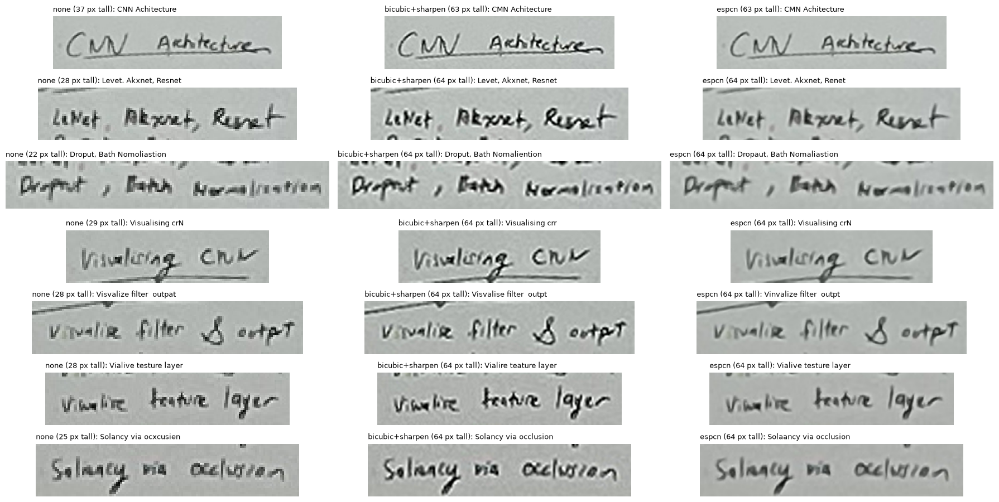

In [23]:
SHOW_METHODS = ["none", "bicubic+sharpen", "espcn"]
match = {g: min(small_lines, key=lambda l: jiwer.cer(g.lower(), l["text0"].lower() or " ")) for g in SMALL_GT}
fig, ax = plt.subplots(len(SMALL_GT), len(SHOW_METHODS), figsize=(6 * len(SHOW_METHODS), 1.3 * len(SMALL_GT)))
for i, g in enumerate(SMALL_GT):
    l = match[g]
    s = float(np.clip(TARGET_H / max(l["height"], 1), 1, MAX_SCALE))
    for j, m in enumerate(SHOW_METHODS):
        im = enlarge(l["crop"], s, m)
        r = rec_model.predict([im])[0]
        ax[i, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax[i, j].set_title(f"{m} ({im.shape[0]} px tall): {plain(r['rec_text'])}", fontsize=9, loc="left")
        ax[i, j].axis("off")
plt.tight_layout(); plt.show()


### 9.4 Upscale the whole text region before detection (faster alternative to tiling)

1. the quick detection (photo shrunk to 1600 px) finds *some* of the writing;
2. nearby boxes are grouped, and a **full-resolution region** (with margin) is cut around each group;
3. each region is **upscaled ×3**, then detected and read; boxes are mapped back to the photo.

If the quick pass finds nothing, it falls back to tiled detection. Writing far from anything the quick pass found can be missed; tiling is the safer choice when everything on the board is needed.


In [24]:
region_rows = []
for name, fn in [
    ("quick detection only (shrunk to 1600 px)", lambda: (det_whole, [])),
    ("tiled full-resolution detection",          lambda: (det_tiled, [])),
    ("region x1 (full resolution, no upscale)",  lambda: upscale_regions_ocr(small_img, det_whole, scale=1, method="none")),
    ("region x3 bicubic+sharpen",                lambda: upscale_regions_ocr(small_img, det_whole, scale=3, method="bicubic+sharpen")),
    ("region x3 espcn",                          lambda: upscale_regions_ocr(small_img, det_whole, scale=3, method="espcn")),
]:
    t0 = time.time(); d, regions = fn(); tt = time.time() - t0
    if name.startswith("quick"):
        tt = t_whole
    elif name.startswith("tiled"):
        tt = t_tiled
    else:
        tt += t_whole                     # region methods also need the quick detection
    cer, per = score_lines(d)
    region_rows.append((name, f"{sum(c < 0.5 for *_, c in per)} / {len(SMALL_GT)}", round(cer, 3), round(tt, 1)))
    if name == "region x3 espcn":
        det_region, small_regions = d, regions
display(pd.DataFrame(region_rows, columns=["approach", "lines found", "mean CER", "time (s)"]).set_index("approach"))

,lines found,mean CER,time (s)
approach,,,
quick detection only (shrunk to 1600 px),4 / 7,0.429,6.0
tiled full-resolution detection,7 / 7,0.160,79.4
"region x1 (full resolution, no upscale)",7 / 7,0.197,9.1
region x3 bicubic+sharpen,7 / 7,0.181,19.2
region x3 espcn,7 / 7,0.197,19.8


#### Regions cut from the photo, and the upscaled region with its detections

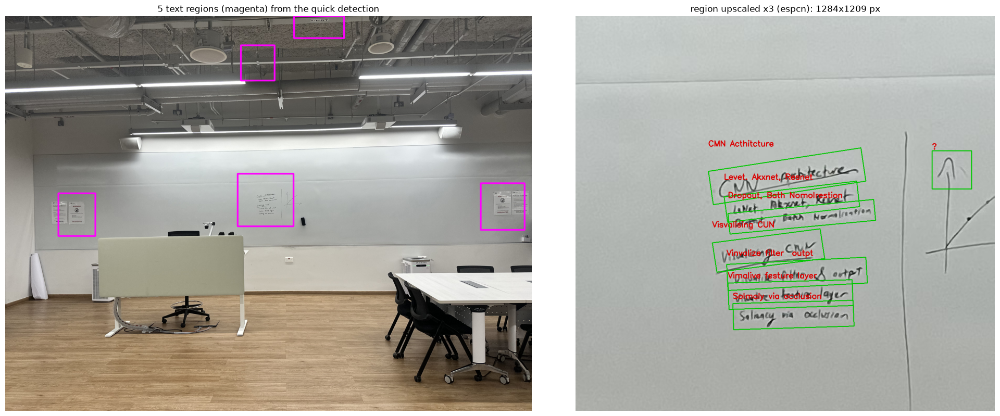

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.3, 1]})
vis = cv2.cvtColor(small_img, cv2.COLOR_BGR2RGB)
for x0, y0, x1, y1 in small_regions:
    cv2.rectangle(vis, (x0, y0), (x1, y1), (255, 0, 255), 12)
ax[0].imshow(vis); ax[0].set_title(f"{len(small_regions)} text regions (magenta) from the quick detection"); ax[0].axis("off")

# the region holding the writing: the one that contains the most ground-truth matches
best = max(small_regions, key=lambda r: sum(r[0] <= best_match(det_region, g)[0][2][:, 0].mean() <= r[2] and
                                             r[1] <= best_match(det_region, g)[0][2][:, 1].mean() <= r[3] for g in SMALL_GT))
x0, y0, x1, y1 = best
up = enlarge(small_img[y0:y1, x0:x1], REGION_SCALE, REGION_METHOD)
s = up.shape[1] / (x1 - x0)
vis = cv2.cvtColor(up, cv2.COLOR_BGR2RGB)
for text, score, poly in det_region:
    p = (np.asarray(poly, float) - [x0, y0]) * s
    if p[:, 0].min() < 0 or p[:, 1].min() < 0 or p[:, 0].max() > up.shape[1] or p[:, 1].max() > up.shape[0]:
        continue
    cv2.polylines(vis, [np.int32(p)], True, (0, 200, 0), 2)
    cv2.putText(vis, plain(text), (int(p[:, 0].min()), int(p[:, 1].min()) - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (220, 0, 0), 2)
ax[1].imshow(vis); ax[1].set_title(f"region upscaled x{REGION_SCALE:g} ({REGION_METHOD}): {up.shape[1]}x{up.shape[0]} px"); ax[1].axis("off")
plt.tight_layout(); plt.show()

**Findings on IMG_4547** (one photo, 7 lines; treat as a pilot)

| approach | lines found | mean CER | time |
|---|---|---|---|
| quick detection (photo shrunk to 1600 px) | 4 / 7 | 0.43 | ~6 s |
| tiled full-resolution detection | 7 / 7 | **0.16** | ~77 s |
| tiled + per-line bicubic+sharpen | 7 / 7 | **0.14** | ~78 s |
| region at full resolution (x1) | 7 / 7 | 0.20 | **~9 s** |
| region x3 bicubic+sharpen / espcn | 7 / 7 | 0.18 / 0.20 | ~19 s |

- **Detecting on a shrunk photo is the main problem** (3 of 7 lines missed). Anything that looks at the writing at **full resolution** finds all 7 lines: tiling (thorough, slow) or a region around the quick detections (fast).
- **Upscaling adds little and inconsistently**: per line, bicubic + sharpening helped slightly; per region, x3 upscaling changed CER by only +/-0.02, and learned super-resolution (ESPCN/FSRCNN/EDSR) was never clearly better than bicubic. On one photo these differences are a few characters, i.e. within noise.
- **Remaining errors are handwriting shapes** (`Levet`, `Akxnet`, `testure`): no upscaling fixes those; that is what fine-tuning the recognizer on IAM is for.
- Next: a controlled shrink-and-restore test (CER vs text height per method) on more photos to settle whether upscaling is worth its cost.


### 9.5 Faster versions (efficiency)

Measured on this Mac (CPU only; PaddlePaddle cannot use the Apple GPU), **text detection dominates the time**: ~6 s per 1600 px image with the medium detector. Three changes:

1. **Mobile text detector** (`PP-OCRv5_mobile_det`) for all detection in this section: ~1 s instead of ~6 s per 1600 px tile, and it found the same lines on IMG_4547.
2. **Tile only the board**: the quick detection → flood-fill board region → tiles only over the board's bounding box (e.g. 6 of 12 tiles on IMG_4547); regions not on the board (ceiling labels) are dropped.
3. **Read every line once**: tiles/regions only *detect*; all boxes are merged, then read in one batch (no reading inside every tile, no duplicate reads in overlaps).


In [26]:
from paddleocr import TextDetection

# Detection-only model for the fast paths. The mobile detector was ~6x faster than the medium one
# on a 1600 px tile (1.0 s vs 6.1 s on this Mac's CPU) and found the same lines on IMG_4547.
FAST_DET_MODEL = "PP-OCRv5_mobile_det"
det_model = TextDetection(model_name=FAST_DET_MODEL)
DET_ARGS = dict(thresh=PREDICT_CONFIG["text_det_thresh"], box_thresh=PREDICT_CONFIG["text_det_box_thresh"],
                unclip_ratio=PREDICT_CONFIG["text_det_unclip_ratio"])
MIN_BOARD_IN_TILE = 0.02      # skip tiles with less than 2% board pixels (ceiling, floor, furniture)


def detect_boxes(img_bgr, limit=None):
    # text boxes only (no reading). limit=1600 shrinks the image to at most 1600 px; None keeps full resolution
    kw = dict(DET_ARGS)
    kw.update(dict(limit_side_len=limit, limit_type="max") if limit else dict(limit_side_len=REGION_MAX, limit_type="max"))
    return [np.asarray(p, float).reshape(-1, 2) for p in det_model.predict(img_bgr, **kw)[0]["dt_polys"]]


def merge_boxes(polys, overlap=0.5):
    # drop boxes that lie mostly inside a bigger one (same line found twice in overlapping tiles/regions)
    return [p for _, _, p in merge_dets([("", 0.0, p) for p in polys], overlap)]


def read_boxes(img_bgr, polys, method="none", target_h=TARGET_H):
    # read every box once, in one batch; each line is cut along its box and optionally enlarged
    if not polys:
        return []
    ims = [enlarge(quad_crop(img_bgr, p), float(np.clip(target_h / max(line_height(p), 1), 1, MAX_SCALE)), method)
           for p in polys]
    return [(r["rec_text"], float(r["rec_score"]), p) for r, p in zip(rec_model.predict(ims), polys)]


def board_mask_from_quick(img_bgr, quick_polys):
    # flood-fill board region grown from the quick detections (None if nothing was found)
    return segment_board_floodfill(img_bgr, quick_polys)[0] if quick_polys else None


def fast_tiled_ocr(img_bgr, method="none", tile=TILE, overlap=OVERLAP):
    # quick detection -> board region -> full-resolution tiles ON THE BOARD only -> merge boxes -> read once
    quick = detect_boxes(img_bgr, limit=1600)
    mask = board_mask_from_quick(img_bgr, quick)
    h, w = img_bgr.shape[:2]
    # tile only the board's bounding box (plus a margin), not the whole photo
    if mask is not None and mask.any():
        ys_, xs_ = np.nonzero(mask[::8, ::8]); m = int(0.02 * max(h, w))
        bx0, by0 = max(0, xs_.min() * 8 - m), max(0, ys_.min() * 8 - m)
        bx1, by1 = min(w, xs_.max() * 8 + 8 + m), min(h, ys_.max() * 8 + 8 + m)
    else:
        bx0, by0, bx1, by1 = 0, 0, w, h
    step = tile - overlap
    def starts(a, b):
        if b - a <= tile:
            return [a]
        st = list(range(a, b - tile + 1, step))
        return st + ([b - tile] if st[-1] + tile < b else [])
    xs, ys = starts(bx0, bx1), starts(by0, by1)
    all_tiles = len(starts(0, w)) * len(starts(0, h))
    polys, n_tiles = [], 0
    for y0 in ys:
        for x0 in xs:
            t = img_bgr[y0:min(y0 + tile, by1), x0:min(x0 + tile, bx1)]
            if mask is not None and (mask[y0:y0 + t.shape[0], x0:x0 + t.shape[1]] > 0).mean() < MIN_BOARD_IN_TILE:
                continue
            n_tiles += 1
            polys += [p + [x0, y0] for p in detect_boxes(t)]
    polys = merge_boxes(polys)
    return read_boxes(img_bgr, polys, method), dict(tiles=n_tiles, of=all_tiles, mask=mask, area=(bx0, by0, bx1, by1))


def fast_region_ocr(img_bgr, scale=REGION_SCALE, method="bicubic+sharpen"):
    # quick detection -> regions around text ON THE BOARD -> upscale region, detect -> read once (per-line enlargement)
    quick = detect_boxes(img_bgr, limit=1600)
    if not quick:
        return fast_tiled_ocr(img_bgr, method)[0], dict(regions=[], mask=None)
    mask = board_mask_from_quick(img_bgr, quick)
    regions = text_regions([("", 0.0, p) for p in quick], img_bgr.shape)
    grow = cv2.dilate(mask, np.ones((25, 25), np.uint8)) if mask is not None else None
    on_board = lambda r: grow is None or grow[(r[1] + r[3]) // 2, (r[0] + r[2]) // 2] > 0
    regions = [r for r in regions if on_board(r)]
    polys = []
    for x0, y0, x1, y1 in regions:
        s = min(scale, REGION_MAX / max(x1 - x0, y1 - y0))
        up = enlarge(img_bgr[y0:y1, x0:x1], s, method)
        sx, sy = up.shape[1] / (x1 - x0), up.shape[0] / (y1 - y0)
        polys += [p / [sx, sy] + [x0, y0] for p in detect_boxes(up)]
    polys = merge_boxes(polys)
    return read_boxes(img_bgr, polys, method), dict(regions=regions, mask=mask)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/zhaobao/.paddlex/official_models/PP-OCRv5_mobile_det`.


#### Old vs new: lines found, CER and time per photo

In [ ]:
FAST_GT = {"IMG_4547": SMALL_GT}
FAST_GT.update({n: ["television", "apple car"] for n in ("IMG_4513", "IMG_4498", "IMG_4500")})

_w = load_upright(WB_DIR / "IMG_4500.jpg"); detect_boxes(_w, 1600); rec_model.predict([_w[:64, :256]])   # warm-up

fast_rows = []
for name, gt in FAST_GT.items():
    img = load_upright(WB_DIR / f"{name}.jpg")
    runs = [("current quick detection (medium, 1600 px)", lambda: (ocr_detect(img), "")),
            ("new tiled (mobile det, board tiles, read once)", lambda: (lambda r: (r[0], f"{r[1]['tiles']}/{r[1]['of']} tiles"))(fast_tiled_ocr(img))),
            ("new region x1", lambda: (lambda r: (r[0], f"{len(r[1]['regions'])} regions"))(fast_region_ocr(img, 1, "none"))),
            ("new region x3 + sharpen", lambda: (lambda r: (r[0], f"{len(r[1]['regions'])} regions"))(fast_region_ocr(img, 3, "bicubic+sharpen")))]
    for label, fn in runs:
        t0 = time.time(); d, note = fn(); tt = time.time() - t0
        cer, per = score_lines(d, gt)
        fast_rows.append((name, label, f"{sum(c < 0.5 for *_, c in per)}/{len(gt)}", round(cer, 3), round(tt, 1), note))
    if name == SMALL_PHOTO:
        fast_rows.append((name, "old tiled (medium det, full OCR per tile), from 9.2", f"{len(SMALL_GT)}/{len(SMALL_GT)}",
                          round(score_lines(det_tiled)[0], 3), round(t_tiled, 1), "12 tiles"))
fast_df = pd.DataFrame(fast_rows, columns=["photo", "method", "lines found", "mean CER", "time (s)", "note"])
display(fast_df.set_index(["photo", "method"]))


**Efficiency findings** (this Mac, CPU)
- Old tiling ~78 s → new tiling **~8–14 s**; region ×3 + sharpen **~7–8 s**; region ×1 **~2–6 s**; the current quick detection ~5 s but misses small text.
- **Recommended default: region ×3 + sharpen** (all lines found on all 4 photos, best CER of the fast options), with **tiling as the fallback** when the quick pass finds no text.
- Cost of the speed-up: the mobile detector is slightly less accurate on the smallest text (IMG_4547: 0.21 with fast tiling vs 0.16 with the old medium-detector tiling). Option if accuracy matters more: mobile detector to *find* regions, medium detector inside the small regions.
- Memory is still ~7 GB because several models are loaded at once (PaddleOCR pipeline + separate detector + recognizer, and YOLO whenever its weights exist); sharing models and loading YOLO only when used is the next saving.



### 9.6 `smart_ocr`: only zoom in / upscale when the text is small

Upscaling every photo wastes time and does nothing for text that is already big enough. `smart_ocr` decides **per photo and per line** from the text height it already measured:

```
quick detection (mobile detector, photo shrunk to 1600 px)
   └─ writing height as the detector saw it (median of boxes on the board)
        ├─ >= DET_MIN_H (20 px) -> keep the quick boxes                      (close / medium photos)
        └─ <  DET_MIN_H          -> re-detect the board's text regions at full resolution
for each line:
   ├─ height in the photo < REC_MIN_H (48 px, the recognizer's input) -> enlarge to ~64 px (bicubic+sharpen), else read as is
   ├─ confidence < 0.8 -> read it the other way too (enlarged <-> plain), keep the more confident
   └─ still < 0.8      -> re-detect just that area at full resolution (loose box from the shrunk photo) and read again
```
Thresholds come from these photos (IMG_4547's writing is ~16 px to the detector and lines were missed; IMG_4513's ~34 px was fine) and should be confirmed on more photos.


In [30]:
DET_MIN_H   = 20      # writing smaller than this (px, as the 1600 px detector sees it) -> re-detect at full resolution
REC_MIN_H   = 48      # text lines shorter than this (px, in the photo) are enlarged before reading (recognizer input = 48 px)
RETRY_CONF  = 0.80    # lines read with lower confidence are read again the other way (enlarged <-> plain); best kept
SMART_METHOD = "bicubic+sharpen"


def _board_boxes(polys, mask):
    # boxes whose centre is on the board (all boxes if there is no board mask)
    if mask is None:
        return polys
    h, w = mask.shape
    return [p for p in polys if mask[int(np.clip(p[:, 1].mean(), 0, h - 1)), int(np.clip(p[:, 0].mean(), 0, w - 1))] > 0] or polys


def smart_ocr(img_bgr):
    # photo -> [(text, confidence, box)], doing extra work only where the text is small. Returns (dets, info)
    t0 = time.time()
    h, w = img_bgr.shape[:2]
    shrink = min(1.0, 1600 / max(h, w))
    info = dict(path="", writing_px_detector=None, enlarged=0, retried=0, redetected=0)

    # 1. quick detection on the shrunk photo
    quick = detect_boxes(img_bgr, limit=1600)
    if not quick:
        polys = fast_tiled_ocr(img_bgr)[0]
        polys = [p for _, _, p in polys]
        info["path"] = "no text in quick pass -> tiled full-resolution detection"
    else:
        # 2. how big is the writing, as the detector saw it? (median line height of boxes on the board)
        mask = board_mask_from_quick(img_bgr, quick)
        writing = _board_boxes(quick, mask)
        det_h = float(np.median([line_height(p) for p in writing])) * shrink
        info["writing_px_detector"] = round(det_h, 1)
        if det_h >= DET_MIN_H:
            polys = quick
            info["path"] = f"text large enough ({det_h:.0f} px >= {DET_MIN_H}) -> quick detections kept"
        else:
            # 3. small writing: re-detect each text region on the board at full resolution
            regions = text_regions([("", 0.0, p) for p in quick], img_bgr.shape)
            if mask is not None:
                grow = cv2.dilate(mask, np.ones((25, 25), np.uint8))
                regions = [r for r in regions if grow[(r[1] + r[3]) // 2, (r[0] + r[2]) // 2] > 0] or regions
            polys = []
            for x0, y0, x1, y1 in regions:
                polys += [p + [x0, y0] for p in detect_boxes(img_bgr[y0:y1, x0:x1])]
            polys = merge_boxes(polys) or quick
            info["path"] = f"small text ({det_h:.0f} px < {DET_MIN_H}) -> {len(regions)} region(s) re-detected at full resolution"

    # 4. read: enlarge only the lines shorter than REC_MIN_H
    crops = [quad_crop(img_bgr, p) for p in polys]
    heights = [line_height(p) for p in polys]
    def prepare(c, lh, big):
        return enlarge(c, float(np.clip(TARGET_H / max(lh, 1), 1, MAX_SCALE)), SMART_METHOD) if big else c
    small = [lh < REC_MIN_H for lh in heights]
    info["enlarged"] = int(sum(small))
    res = rec_model.predict([prepare(c, lh, s) for c, lh, s in zip(crops, heights, small)]) if crops else []
    out = [[r["rec_text"], float(r["rec_score"])] for r in res]

    # 5. low-confidence lines: try the other way, keep the more confident reading
    retry = [i for i, (_, sc) in enumerate(out) if sc < RETRY_CONF and (small[i] or heights[i] < 2 * REC_MIN_H)]
    if retry:
        res2 = rec_model.predict([prepare(crops[i], heights[i], not small[i]) for i in retry])
        for i, r in zip(retry, res2):
            if float(r["rec_score"]) > out[i][1]:
                out[i] = [r["rec_text"], float(r["rec_score"])]
    info["retried"] = len(retry)

    # 6. still doubtful: the box itself may be loose (quick boxes come from the shrunk photo), so re-detect just
    #    that area at full resolution and read again; keep the new reading if it is more confident
    final, redetected = [], 0
    for (text, sc), p in zip(out, polys):
        if sc >= RETRY_CONF:
            final.append((text, sc, p)); continue
        redetected += 1
        lh = line_height(p); m = 0.5 * lh
        x0, y0 = (p.min(0) - m).astype(int); x1, y1 = (p.max(0) + m).astype(int)
        x0, y0, x1, y1 = max(x0, 0), max(y0, 0), min(x1, w), min(y1, h)
        sub = [q + [x0, y0] for q in detect_boxes(img_bgr[y0:y1, x0:x1])]
        new = read_boxes(img_bgr, sub, SMART_METHOD) if sub else []
        if new and max(n[1] for n in new) > sc:
            final += new
        else:
            final.append((text, sc, p))
    info["redetected"] = redetected
    info["seconds"] = round(time.time() - t0, 1)
    return final, info


#### Current pipeline vs always upscaling vs `smart_ocr`

In [31]:
SMART_GT = dict(FAST_GT)
SMART_GT.update({n: ["Animal"] for n in ("IMG_4493", "IMG_4494", "IMG_4495")})

smart_rows = []
for name, gt in SMART_GT.items():
    img = load_upright(WB_DIR / f"{name}.jpg")
    for label, fn in [("current quick detection (medium, 1600 px)", lambda: (ocr_detect(img), None)),
                      ("always: region x3 + sharpen", lambda: fast_region_ocr(img, 3, "bicubic+sharpen")),
                      ("smart_ocr", lambda: smart_ocr(img))]:
        t0 = time.time(); d, i = fn(); tt = time.time() - t0
        cer, per = score_lines(d, gt)
        note = "" if label != "smart_ocr" else (f"{i['path']}; enlarged {i['enlarged']}/{len(d)} lines, "
                                                 f"retried {i['retried']}, re-detected {i['redetected']}")
        smart_rows.append((name, label, f"{sum(c < 0.5 for *_, c in per)}/{len(gt)}", round(cer, 3), round(tt, 1), note))
smart_df = pd.DataFrame(smart_rows, columns=["photo", "method", "lines found", "mean CER", "time (s)", "what smart_ocr did"])
pd.set_option("display.max_colwidth", 120)
display(smart_df.set_index(["photo", "method"]))
print(smart_df.groupby("method")[["mean CER", "time (s)"]].mean().round(3))

lines found  mean CER  \
photo    method                                                            
IMG_4547 current quick detection (medium, 1600 px)         4/7     0.429   
         always: region x3 + sharpen                       7/7     0.175   
         smart_ocr                                         7/7     0.181   
IMG_4513 current quick detection (medium, 1600 px)         2/2     0.000   
         always: region x3 + sharpen                       2/2     0.000   
         smart_ocr                                         2/2     0.000   
IMG_4498 current quick detection (medium, 1600 px)         2/2     0.156   
         always: region x3 + sharpen                       2/2     0.000   
         smart_ocr                                         2/2     0.000   
IMG_4500 current quick detection (medium, 1600 px)         2/2     0.000   
         always: region x3 + sharpen                       2/2     0.000   
         smart_ocr                                         2/2     0.000   
IMG_4493 current quick detection (medium, 1600 px)         1/1     0.000   
         always: region x3 + sharpen                       1/1     0.000   
         smart_ocr                                         1/1     0.000   
IMG_4494 current quick detection (medium, 1600 px)         1/1     0.167   
         always: region x3 + sharpen                       1/1     0.000   
         smart_ocr                                         1/1     0.000   
IMG_4495 current quick detection (medium, 1600 px)         1/1     0.000   
         always: region x3 + sharpen                       1/1     0.000   
         smart_ocr                                         1/1     0.000   

                                                    time (s)  \
photo    method                                                
IMG_4547 current quick detection (medium, 1600 px)       6.3   
         always: region x3 + sharpen                     8.5   
         smart_ocr                                       5.7   
IMG_4513 current quick detection (medium, 1600 px)       5.6   
         always: region x3 + sharpen                     7.0   
         smart_ocr                                       1.6   
IMG_4498 current quick detection (medium, 1600 px)       5.2   
         always: region x3 + sharpen                     6.8   
         smart_ocr                                       1.3   
IMG_4500 current quick detection (medium, 1600 px)       4.7   
         always: region x3 + sharpen                     7.1   
         smart_ocr                                       1.1   
IMG_4493 current quick detection (medium, 1600 px)       4.6   
         always: region x3 + sharpen                     7.6   
         smart_ocr                                       1.8   
IMG_4494 current quick detection (medium, 1600 px)       4.7   
         always: region x3 + sharpen                     7.8   
         smart_ocr                                       1.2   
IMG_4495 current quick detection (medium, 1600 px)       5.3   
         always: region x3 + sharpen                     8.3   
         smart_ocr                                       0.9   

                                                                                                                                                       what smart_ocr did  
photo    method                                                                                                                                                            
IMG_4547 current quick detection (medium, 1600 px)                                                                                                                         
         always: region x3 + sharpen                                                                                                                                       
         smart_ocr                                  small text (16 px < 20) -> 2 region(s) re-detected at full resolution; enlarged 20/23 lin

                                           mean CER  time (s)
method                                                       
always: region x3 + sharpen                   0.025     7.586
current quick detection (medium, 1600 px)     0.107     5.200
smart_ocr                                     0.026     1.943



**`smart_ocr` findings** (7 photos)
- Close / medium photos take the quick path (~1–2 s) and nothing is enlarged unless a line is small; the far photo (IMG_4547) takes the full-resolution path (~5–6 s) and all 7 lines are found.
- It matched or beat both the current pipeline (~5 s per photo, misses small text) and always-upscaling (~6–8 s per photo).
- The low-confidence re-detection was needed on IMG_4493: the quick box around "Animal" (from the shrunk photo) was too loose on this steep view.
- Not yet combined with perspective correction (section 8); that is the next step for a single photo → text function.


### 9.7 Original vs conditional zoom-in comparison

The first figure shows the complete source photograph next to the full-resolution region selected by `smart_ocr`. The second figure shows each native text-line crop beside the exact enlarged crop sent to the recognizer. A native crop is centred on a canvas matching the enlarged output so that the size change remains visible.

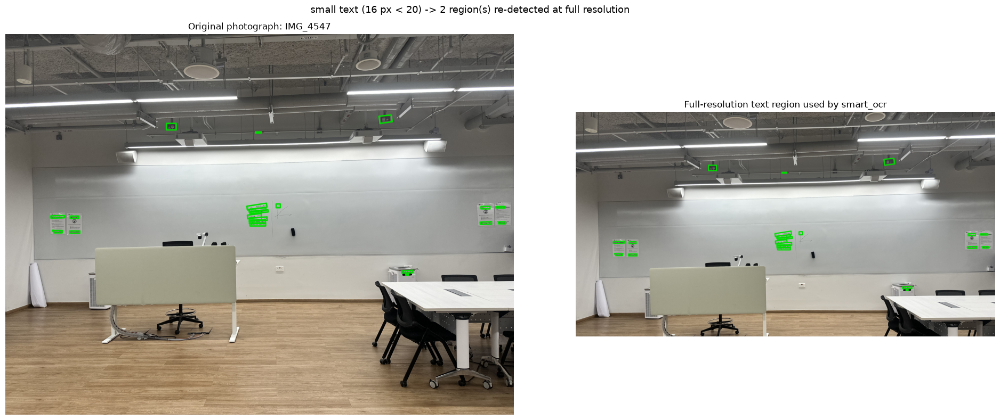

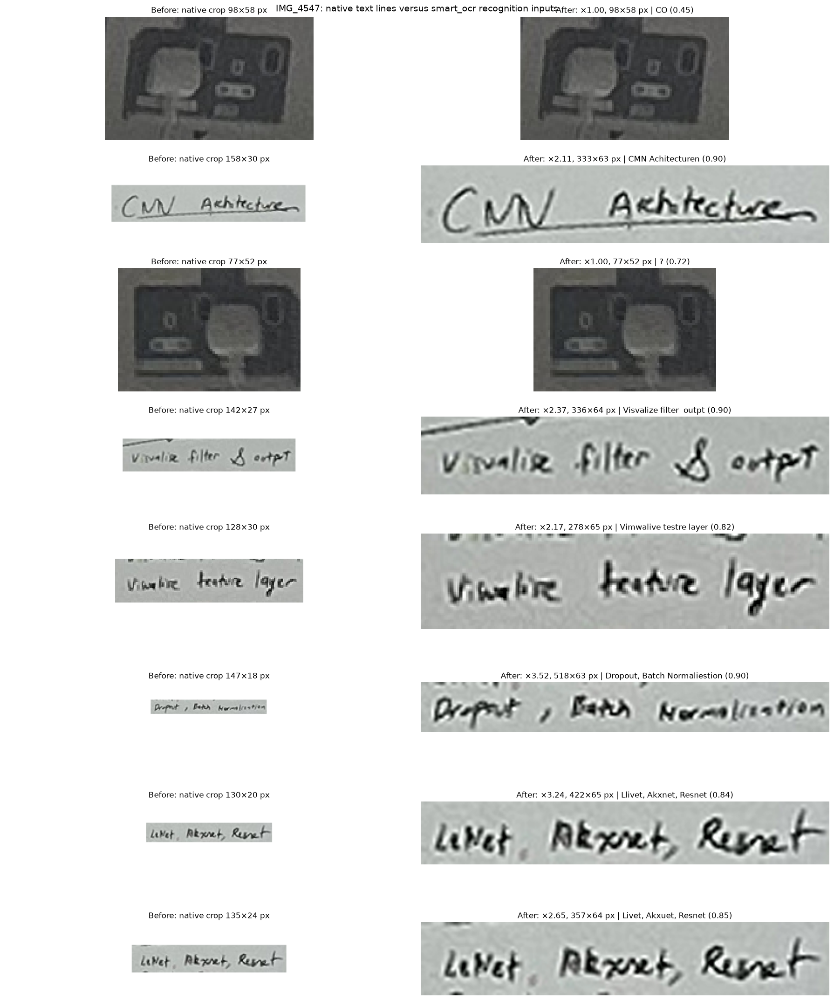

smart_ocr decision: small text (16 px < 20) -> 2 region(s) re-detected at full resolution
Writing height seen by detector: 16.2 px
Lines enlarged: 20 of 23
Low-confidence retries: 7
Local re-detections: 5
Saved: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/outputs/zoom_comparison/IMG_4547_original_vs_region.png
Saved: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/outputs/zoom_comparison/IMG_4547_before_vs_enlarged_lines.png


In [32]:
ZOOM_COMPARE_PHOTO = "IMG_4547"       # far-away writing used in the Section 9 experiment
ZOOM_OUT = ROOT / "outputs" / "zoom_comparison"
ZOOM_OUT.mkdir(parents=True, exist_ok=True)

zoom_path = WB_DIR / f"{ZOOM_COMPARE_PHOTO}.jpg"
zoom_img = load_upright(zoom_path)
zoom_dets, zoom_info = smart_ocr(zoom_img)
assert zoom_dets, f"smart_ocr found no text in {zoom_path.name}"

# Figure 1: complete photograph versus the text region at original camera resolution.
original_vis = cv2.cvtColor(zoom_img.copy(), cv2.COLOR_BGR2RGB)
all_pts = []
for text, score, poly in zoom_dets:
    p = np.asarray(poly, dtype=np.float32).reshape(-1, 2)
    all_pts.append(p)
    cv2.polylines(original_vis, [np.int32(p).reshape(-1, 1, 2)], True, (0, 220, 0), 10)

all_pts = np.vstack(all_pts)
h, w = zoom_img.shape[:2]
x0, y0 = all_pts.min(axis=0); x1, y1 = all_pts.max(axis=0)
mx, my = max(100, 0.20 * (x1 - x0)), max(100, 0.35 * (y1 - y0))
x0, y0 = int(max(0, x0 - mx)), int(max(0, y0 - my))
x1, y1 = int(min(w, x1 + mx)), int(min(h, y1 + my))
region_vis = original_vis[y0:y1, x0:x1]

fig, ax = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].imshow(original_vis)
ax[0].set_title(f"Original photograph: {ZOOM_COMPARE_PHOTO}")
ax[1].imshow(region_vis)
ax[1].set_title("Full-resolution text region used by smart_ocr")
for a in ax: a.axis("off")
fig.suptitle(zoom_info["path"], fontsize=13)
plt.tight_layout()
region_output = ZOOM_OUT / f"{ZOOM_COMPARE_PHOTO}_original_vs_region.png"
plt.savefig(region_output, dpi=180, bbox_inches="tight")
plt.show()

# Figure 2: native line crops versus the enlarged inputs sent to recognition.
line_examples = []
for text, score, poly in zoom_dets:
    native = quad_crop(zoom_img, poly)
    height = line_height(poly)
    scale = float(np.clip(TARGET_H / max(height, 1), 1, MAX_SCALE)) if height < REC_MIN_H else 1.0
    enlarged = enlarge(native, scale, SMART_METHOD)
    canvas = np.full_like(enlarged, 255)
    oy = (canvas.shape[0] - native.shape[0]) // 2
    ox = (canvas.shape[1] - native.shape[1]) // 2
    canvas[oy:oy + native.shape[0], ox:ox + native.shape[1]] = native
    line_examples.append((text, score, height, scale, canvas, enlarged, native.shape, enlarged.shape))

n = min(len(line_examples), 8)
fig, axes = plt.subplots(n, 2, figsize=(18, max(3, 2.8 * n)), squeeze=False)
for row, (text, score, height, scale, native_canvas, enlarged, native_shape, enlarged_shape) in zip(axes, line_examples[:n]):
    row[0].imshow(cv2.cvtColor(native_canvas, cv2.COLOR_BGR2RGB))
    row[0].set_title(f"Before: native crop {native_shape[1]}×{native_shape[0]} px")
    row[1].imshow(cv2.cvtColor(enlarged, cv2.COLOR_BGR2RGB))
    row[1].set_title(f"After: ×{scale:.2f}, {enlarged_shape[1]}×{enlarged_shape[0]} px | {plain(text)} ({score:.2f})")
    for a in row: a.axis("off")
fig.suptitle(f"{ZOOM_COMPARE_PHOTO}: native text lines versus smart_ocr recognition inputs", fontsize=14)
plt.tight_layout()
line_output = ZOOM_OUT / f"{ZOOM_COMPARE_PHOTO}_before_vs_enlarged_lines.png"
plt.savefig(line_output, dpi=180, bbox_inches="tight")
plt.show()

print("smart_ocr decision:", zoom_info["path"])
print("Writing height seen by detector:", zoom_info["writing_px_detector"], "px")
print("Lines enlarged:", zoom_info["enlarged"], "of", len(zoom_dets))
print("Low-confidence retries:", zoom_info["retried"])
print("Local re-detections:", zoom_info["redetected"])
print("Saved:", region_output)
print("Saved:", line_output)
